# Task 16 — Review intelligence: a weekly reply queue, a monthly digest and product summaries that cite their reviews

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Amazon Fine Food Reviews](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews) — 568,454 Amazon US reviews, Oct 1999 – Oct 2012, from Stanford SNAP (CC0)
**Task family:** NLP: text classification, topic drift, extractive summarisation, a rule-built product graph · **Companion tasks:** `03_complaint_triage_text.ipynb` (text classification), `04_erp_document_rag.ipynb` (retrieval without an LLM)

---

## The task card

> **Board question.** *About 3,200 reviews of our products arrive every week and the customer team can write 300 replies. Which 300 should it write, what are customers telling us this month, and can product managers get summaries that cite the reviews behind them?*

**Business context.** A food retailer sells online: reviews land on a review platform, replies go out from a CRM, and allergen data sits in an incomplete product-information system. The queue is Session 01's *batch prediction with a human in the loop*. The scorer must also triage e-mails and social posts, which have no star, so it reads **text only**; reviews, where customers state a verdict, train it. Allergens give summaries a legal edge (Regulation (EU) No 1169/2011 lists 14).

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given text model behind a **weekly reply queue**, packaged and reproducible, evaluated forward in time at the team's capacity;
2. a **monthly digest** of topics, with drift tracked year by year;
3. **product summaries** with citations, and a **rule-built product graph** validated with SHACL and tested in an ablation;
4. the **operational wrapper** and a one-page **recommendation for the head of customer service**.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Weekly batch plus request-time scoring; review platform, CRM and product data as legacy estate |
| 2 · MLOps | De-duplication as a data contract, forward evaluation, a gate on precision at capacity, drift |
| 3 · Semantic layer | A product–brand–allergen graph with evidence, SHACL, the EU allergen list as vocabulary |
| 4 · LLM/RAG | Grounded summaries and reply drafts with citations (Stretch) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. No LLM in the baseline. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. Four traps are measured and flagged ⚠; turning each into a test is part of the task.

**Honesty note.** The data is **real**: Amazon customers' reviews, crawled by McAuley and Leskovec (2013), released under CC0. User ids are pseudonymised on load and names dropped; five truncated sentences are printed. "Needs a response" is a proxy from the star: nobody recorded which reviews a team answered. The retailer is a scenario.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: copies, the unhappy share, the label | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | Text-only triage forward in time, the 300-a-week operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | Drift over thirteen years and the topic digest, product summaries and the product graph, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_reviews` (Section 1); the copy merge (Section 2, inline code that becomes `dedup.py`); `fit_text_model` and `weekly_queue` (Section 3); the topic digest (Section 6, inline code); `sentences`, `mmr`, `summarise`, `aspect_reference`, `aspect_recall`, `other_brand`, `summarise_with_graph`, `headline_allergens`, `allergen_cover` and `generate` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** after merging copies, 100,000 training reviews (2010–2011), 41,440 validation and 94,382 test (29 weeks, Apr–Oct 2012); alpha 2e-06; test AUPRC 0.831 against a base rate of 0.160; at 300 replies a week, precision 0.881 and recall 0.511; summariser with the graph: aspect recall 0.705 and allergen coverage 0.948.
- **Runtime:** about 2–3 minutes on a laptop (143 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, time, json, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.csv as pc
import networkx as nx
import scipy.sparse as sp
from IPython.display import display
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer, TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import SGDClassifier
from sklearn.decomposition import NMF
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, accuracy_score
from rdflib import Graph, Namespace, Literal, RDF, RDFS, XSD
import pyshacl

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 90)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "snap/amazon-fine-food-reviews"
CSV_FILE = "Reviews.csv"                 # the SQLite copy holds the same table; it is not needed
UID_SALT = "ari3217-task16"              # pseudonymisation salt; production keeps a secret key outside Git (task E2)
N_JOBS = 1                               # one thread per model on this shared machine; raise it on your laptop
# forward-in-time windows (weeks run Monday–Sunday; the data ends on 26 Oct 2012)
TRAIN_START, TRAIN_END = pd.Timestamp("2010-01-01"), pd.Timestamp("2012-01-02")   # train: 2010–2011
VALID_END = pd.Timestamp("2012-04-02")   # validation: 2 Jan – 1 Apr 2012 (13 weeks; regularisation chosen here)
TEST_END = pd.Timestamp("2012-10-22")    # test: 2 Apr – 21 Oct 2012 (29 complete weeks, frozen)
N_TRAIN = 100_000                        # training reviews sampled from 2010–2011; lower it on a small laptop
HASH_FEATURES = 2 ** 20                  # hashed unigram + bigram space
ALPHAS = [1e-6, 2e-6, 4e-6]              # L2 strengths tried on validation
# business constants (assumptions — task C3)
REPLIES_PER_WEEK = 300                   # replies the customer team can write in a week
# drift on a time axis
FROZEN_YEARS = [2007, 2008]              # the frozen model's training years (Section 6)
DRIFT_PER_YEAR = 15_000                  # reviews sampled per year for the drift study
N_TOPICS = 12                            # NMF topics, fitted on 2010–2011 only
# summaries and the product graph
SUMMARY_START = pd.Timestamp("2012-01-01")   # summaries and the golden set cover Jan–Oct 2012
MIN_REVIEWS_GOLD = 40                    # a golden product needs this many distinct reviews on its page in the window
N_GOLD = 60                              # golden products for the aspect check (one per listing)
K_POS, K_NEG = 3, 2                      # summary sentences from 4–5-star and from 1–2-star reviews
KG_START, KG_MIN_REVIEWS = pd.Timestamp("2011-01-01"), 25   # the graph covers listings with ≥ 25 reviews since 2011

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "amazon_fine_food", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn, rdflib
print(f"pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_reviews`; pseudonymisation happens there.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `snap/amazon-fine-food-reviews`, from Stanford SNAP (McAuley and Leskovec, WWW 2013) |
| **Licence** | CC0: Public Domain |
| **Provenance** | Real Amazon US reviews up to the October 2012 crawl; the description says other categories are included |
| **Size** | 568,454 rows; 74,258 product ids; 256,059 users; 8 Oct 1999 – 26 Oct 2012; 393,606 distinct reviews |
| **Files** | `Reviews.csv` (301 MB, used); `database.sqlite` (373 MB, the same table) |
| **Schema** | `Id`, `ProductId`, `UserId`, `ProfileName`, `HelpfulnessNumerator`, `HelpfulnessDenominator`, `Score` (1–5), `Time` (Unix seconds), `Summary` (the title), `Text` (with HTML) |
| **Label** | None ships; `Score ≤ 2` = "needs a response" (Section 2) |
| **Window used here** | Train 2010–2011 (100,000 of 171,799 distinct reviews); validation 2 Jan – 1 Apr 2012 (41,440); test 2 Apr – 21 Oct 2012 (94,382; 29 weeks); 15,000 a year for drift |
| **PII** | `UserId` becomes a salted SHA-256 pseudonym and `ProfileName` is dropped on load; printouts of review text are minimal |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **One review, many pages.** 30.8 % of rows copy another: the same user's text on 2–199 product ids, the variants of one listing. (Trap 1.)
2. ⚠ **Votes are counted at the crawl**: 8.4 per 2006 review, 0.79 per 2012 review. (Trap 2.)
3. ⚠ **The title is a verdict**, typed with the star. (Trap 3.)
4. ⚠ **Five stars dominate**; the 1–2-star share rose from 10 % (2007) to 16 % (2012). (Trap 4.)
5. **Times are dates** (all midnight): a week is the natural grain.
6. **HTML**: line breaks in 99,796 distinct reviews, links in 7,815; stripped first.
7. **Not only food**: the largest new listing of 2012 is a shampoo (Section 6); the rules put 14 listings in a non-food category.
8. **Small errors**: 1,309 page rows repeat a review on the same page; 86 copied reviews differ in stars across pages. The first appearance wins.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_reviews() -> pd.DataFrame:
    '''All 568k reviews with tidy column names; user ids pseudonymised and profile names dropped on load; cached as Parquet.'''
    cache = PROCESSED / "16_reviews.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    df = pc.read_csv(get_raw(CSV_FILE), parse_options=pc.ParseOptions(newlines_in_values=True)).to_pandas()
    # ---- governance on load: a salted hash replaces the user id; the profile name never leaves this cell ----
    df["uid"] = [hashlib.sha256((UID_SALT + u).encode()).hexdigest()[:12] for u in df["UserId"]]
    df = df.drop(columns=["UserId", "ProfileName"])
    df = df.rename(columns={"Id": "review_id", "ProductId": "product_id", "HelpfulnessNumerator": "helpful_yes",
                            "HelpfulnessDenominator": "helpful_votes", "Score": "score", "Time": "date",
                            "Summary": "summary", "Text": "text_html"})
    df["date"] = pd.to_datetime(df["date"], unit="s")
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

raw = load_reviews()
print(f"{len(raw):,} reviews · {raw.product_id.nunique():,} products · {raw.uid.nunique():,} pseudonymised users · "
      f"{raw.date.min():%d %b %Y} → {raw.date.max():%d %b %Y} · times at midnight: {(raw.date == raw.date.dt.normalize()).mean():.0%} · "
      f"{raw.memory_usage(deep=True).sum()/1e6:.0f} MB")
raw.head(3)[["review_id", "product_id", "uid", "score", "helpful_yes", "helpful_votes", "date"]]

568,454 reviews · 74,258 products · 256,059 pseudonymised users · 08 Oct 1999 → 26 Oct 2012 · times at midnight: 100% · 315 MB


,review_id,product_id,uid,score,helpful_yes,helpful_votes,date
0,1,B001E4KFG0,2e25d3a58fa3,5,1,1,2011-04-27
1,2,B00813GRG4,4ac40af0ebfe,1,0,0,2012-09-07
2,3,B000LQOCH0,9cfe19d084b9,4,1,1,2008-08-18


## 2 · First look: one review on many pages, a rising unhappy share, and the label

*Part A · Explore · read; the copy merge here becomes C1's tested data contract.*

How many *distinct* reviews are there, how is the star mix moving, and what does the team's week look like? Copies are merged on (pseudonymised user, text), keeping the first appearance; product ids that share a review are joined into **listings** (connected components).

In [3]:
# One review, many pages: the same user's identical text on several product ids is ONE review
raw = raw.sort_values(["date", "review_id"], kind="stable").reset_index(drop=True)
raw["rid"] = raw.groupby(["uid", "text_html"], sort=False).ngroup()      # review id = order of first appearance
pages = raw[["review_id", "product_id", "rid", "date", "score"]]         # every page row points at its review
rv = raw[~raw.rid.duplicated()].drop(columns=["uid"]).reset_index(drop=True)   # one row per distinct review; uid no longer needed
assert (rv.rid.values == np.arange(len(rv))).all()
n_rows = len(raw)
del raw; import gc; gc.collect()
rv["n_pages"] = pages.groupby("rid").size().values
html_br, html_a = rv.text_html.str.contains("<br", regex=False).sum(), rv.text_html.str.contains("<a href", regex=False).sum()
rv["text"] = rv.text_html.str.replace(r"(?:<[^>]+>|\s)+", " ", regex=True).str.strip()
rv = rv.drop(columns=["text_html"])

# Listings: product ids that show the same reviews are variants of one listing (connected components)
G = nx.Graph(); G.add_nodes_from(pages.product_id.unique())
shared = pages[pages.rid.isin(rv.rid[rv.n_pages > 1])].drop_duplicates(["rid", "product_id"])
G.add_edges_from(zip(shared.groupby("rid").product_id.transform("first").values, shared.product_id.values))
listing_of = pd.Series({p: f"L{i:05d}" for i, comp in enumerate(sorted(nx.connected_components(G), key=min)) for p in comp})
rv["listing"] = rv.product_id.map(listing_of)
sizes = listing_of.value_counts()
same_page_twice = pages.duplicated(["product_id", "rid"]).sum()
score_conflicts = pages.groupby("rid").score.nunique().gt(1).sum()

y_all = (rv.score <= 2).astype(int).values                              # the label: 1–2 stars "needs a response" (Section 2)
rv["y"] = y_all
rv["year"] = rv.date.dt.year
print(f"{n_rows:,} rows → {len(rv):,} distinct reviews; {1 - len(rv)/n_rows:.1%} of rows are copies · "
      f"{(rv.n_pages > 1).sum():,} reviews shown on 2–{rv.n_pages.max()} product pages")
print(f"{len(sizes):,} listings from {len(listing_of):,} product ids: {(sizes > 1).sum():,} have 2–{sizes.max()} variants and hold "
      f"{rv.listing.isin(sizes[sizes > 1].index).mean():.0%} of distinct reviews · same review twice on one page: {same_page_twice:,} · "
      f"copies whose star differs: {score_conflicts} · HTML line breaks in {html_br:,} reviews, links in {html_a:,}")

by_year = rv[rv.year >= 2004].groupby("year").agg(reviews=("review_id", "size"), needs_response=("y", "mean"),
                                                   five_star=("score", lambda s: (s == 5).mean()), three_star=("score", lambda s: (s == 3).mean()),
                                                   votes_per_review=("helpful_votes", "mean"))
by_year["rows incl. copies"] = pages[pages.date.dt.year >= 2004].groupby(pages.date.dt.year).size()
display(by_year.style.format({"reviews": "{:,}", "rows incl. copies": "{:,}", "needs_response": "{:.1%}", "five_star": "{:.1%}",
                              "three_star": "{:.1%}", "votes_per_review": "{:.2f}"}))

568,454 rows → 393,606 distinct reviews; 30.8% of rows are copies · 58,026 reviews shown on 2–199 product pages
65,213 listings from 74,258 product ids: 3,949 have 2–61 variants and hold 30% of distinct reviews · same review twice on one page: 1,309 · copies whose star differs: 86 · HTML line breaks in 99,796 reviews, links in 7,815


,reviews,needs_response,five_star,three_star,votes_per_review,rows incl. copies
year,,,,,,
2004,444,6.8%,74.5%,3.2%,7.91,561
2005,"1,063",8.4%,75.2%,4.3%,7.91,"1,335"
2006,"4,726",12.5%,68.8%,5.6%,8.41,"6,671"
2007,"15,758",10.0%,70.4%,5.9%,5.16,"22,300"
2008,"23,101",10.4%,68.3%,6.5%,3.94,"34,163"
2009,"37,865",12.0%,66.3%,7.1%,3.72,"55,326"
2010,"57,961",14.0%,65.4%,7.2%,2.98,"85,884"
2011,"113,433",15.3%,62.2%,8.1%,1.92,"163,299"
2012,"139,094",16.1%,61.7%,7.9%,0.79,"198,659"


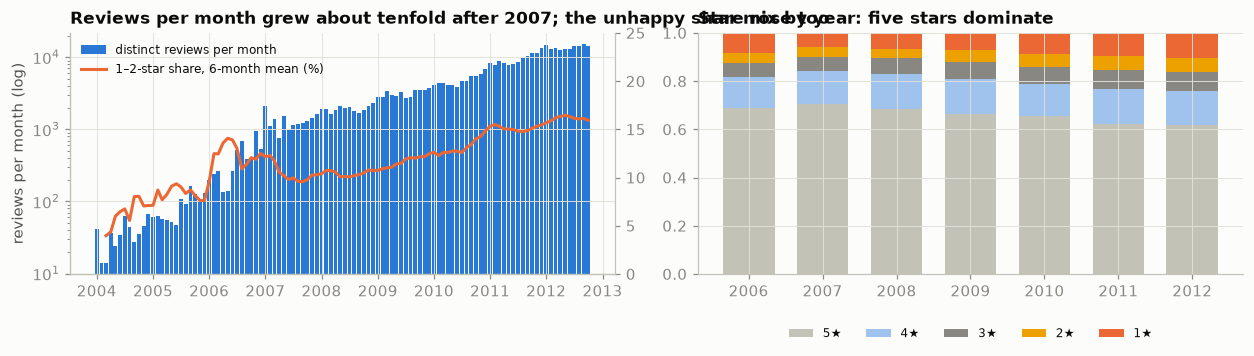

weeks in 2010–Oct 2012: 771–4,163 distinct reviews, of which 87–654 with 1–2 stars; 2012 weeks to 21 Oct: 3,234 reviews and 522 unhappy ones a week on average


In [4]:
monthly = rv[rv.date >= "2004-01-01"].groupby(rv.date.dt.to_period("M")).agg(n=("y", "size"), neg=("y", "mean"))
weekly = rv[(rv.date >= TRAIN_START) & (rv.date < TEST_END)].groupby(rv.date.dt.to_period("W")).agg(n=("y", "size"), neg=("y", "sum"))
weekly = weekly.iloc[1:]                                                 # drop the partial first week

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax = axes[0]
ax.bar(monthly.index.to_timestamp(), monthly.n, width=25, color=SERIES[0], label="distinct reviews per month")
ax.set_yscale("log"); ax.set_ylabel("reviews per month (log)")
ax2 = ax.twinx(); ax2.plot(monthly.index.to_timestamp(), monthly.neg.rolling(6, min_periods=3).mean() * 100, color=SERIES[1], lw=2, label="1–2-star share, 6-month mean (%)")
ax2.set_ylim(0, 25); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("Reviews per month grew about tenfold after 2007; the unhappy share rose too")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
ax = axes[1]
stars = rv[rv.year >= 2006].groupby("year").score.value_counts(normalize=True).unstack()
bottom = np.zeros(len(stars))
for s_, c in zip([5, 4, 3, 2, 1], ["#c3c2b7", "#9fc3ec", MUTED, SERIES[3], SERIES[1]]):
    ax.bar(stars.index, stars[s_], bottom=bottom, color=c, label=f"{s_}★", width=0.7); bottom += stars[s_].values
ax.set_ylim(0, 1); ax.set_title("Star mix by year: five stars dominate"); ax.legend(fontsize=8, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.show()
print(f"weeks in 2010–Oct 2012: {weekly.n.min():,}–{weekly.n.max():,} distinct reviews, of which {weekly.neg.min()}–{weekly.neg.max()} with 1–2 stars; "
      f"2012 weeks to 21 Oct: {weekly.n[weekly.index.start_time >= '2012-01-02'].mean():,.0f} reviews and "
      f"{weekly.neg[weekly.index.start_time >= '2012-01-02'].mean():,.0f} unhappy ones a week on average")

Distinct reviews grew from 15,758 in 2007 to 139,094 in ten months of 2012. A 2012 week brings about 3,234 reviews, 522 of them unhappy, against 300 replies.

**"Needs a response" means one or two stars**: the customer's own verdict, and the only label the data offers. Three-star reviews count as no reply needed (task C3 tests the alternative). On reviews a star filter reproduces this label, so the model reads **text only**: its job is the channels without a star; reviews are where it learns and is tested, star hidden.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Triage from the text alone, forward in time

*Part B · Given model · package `fit_text_model` and `weekly_queue` unchanged and reproduce the numbers (C2).*

Train on 2010–2011, choose the regularisation on the first 13 weeks of 2012, report once on the next 29. Unigrams and bigrams are **hashed** into 2²⁰ columns, weighted by TF-IDF fitted on training rows, and fed to logistic regression fitted by stochastic gradient descent. Hashing is an architecture choice: no vocabulary to fit, version or leak across time, and identical features in batch and online scoring. The price is nameless columns; a training-sample vocabulary names the strongest.

**AUPRC** compares models; **precision and recall at 300 replies a week** (each week's top 300) talk to the team.

In [5]:
tr_pool = rv.index[(rv.date >= TRAIN_START) & (rv.date < TRAIN_END)].values
tr = np.sort(rng.choice(tr_pool, min(N_TRAIN, len(tr_pool)), replace=False))
va = rv.index[(rv.date >= TRAIN_END) & (rv.date < VALID_END)].values
te = rv.index[(rv.date >= VALID_END) & (rv.date < TEST_END)].values
# rows for the drift study (Section 6): a fixed sample per year; 2010–2012 reuse the rows above
drift = {}
for yr in range(2007, 2013):
    pool = (tr if yr in (2010, 2011) else np.r_[va, te] if yr == 2012 else rv.index[rv.year == yr].values)
    pool = pool[rv.year.values[pool] == yr]
    drift[yr] = np.sort(rng.choice(pool, min(DRIFT_PER_YEAR, len(pool)), replace=False))

need = np.unique(np.concatenate([tr, va, te] + list(drift.values())))
t0 = time.time()
hv = HashingVectorizer(ngram_range=(1, 2), n_features=HASH_FEATURES, alternate_sign=False, norm=None, dtype=np.float32)
HX = sp.vstack([hv.transform(rv.text.values[need[i:i + 40_000]]) for i in range(0, len(need), 40_000)]).tocsr()   # stateless: nothing to fit or leak
row_of = pd.Series(np.arange(len(need)), index=need)
H = lambda idx: HX[row_of[idx].values]
print(f"hashed {len(need):,} reviews in {time.time()-t0:.0f}s · train {len(tr):,} (of {len(tr_pool):,}) · valid {len(va):,} · test {len(te):,} · "
      f"1–2-star share: train {y_all[tr].mean():.1%}, valid {y_all[va].mean():.1%}, test {y_all[te].mean():.1%}")

def fit_text_model(idx, alpha, extra=None):
    '''TF-IDF weights fitted on the training rows only, then logistic regression by SGD. Returns a scoring function.'''
    tf = TfidfTransformer(sublinear_tf=True).fit(H(idx))
    X = tf.transform(H(idx))
    if extra is not None:
        X = sp.hstack([X, extra(idx)]).tocsr()
    m = SGDClassifier(loss="log_loss", alpha=alpha, max_iter=20, tol=None, random_state=SEED, n_jobs=N_JOBS).fit(X, y_all[idx])
    def score(j, extra_fn=extra):
        Xj = tf.transform(H(j))
        if extra_fn is not None:
            Xj = sp.hstack([Xj, extra_fn(j)]).tocsr()
        return m.decision_function(Xj)
    score.model, score.tfidf = m, tf
    return score

t0 = time.time()
cand = {a: fit_text_model(tr, a) for a in ALPHAS}
val_auprc = {a: average_precision_score(y_all[va], f(va)) for a, f in cand.items()}
ALPHA = max(val_auprc, key=val_auprc.get)
triage = cand[ALPHA]
s_va, s_te = triage(va), triage(te)
print(f"validation AUPRC by alpha: { {f'{a:g}': round(v, 4) for a, v in val_auprc.items()} } → alpha {ALPHA:g} · {time.time()-t0:.0f}s")
print(f"test (Apr–Oct 2012): AUPRC {average_precision_score(y_all[te], s_te):.3f} · ROC-AUC {roc_auc_score(y_all[te], s_te):.3f} · "
      f"base rate {y_all[te].mean():.3f}")

hashed 280,822 reviews in 23s · train 100,000 (of 171,799) · valid 41,440 · test 94,382 · 1–2-star share: train 14.9%, valid 16.5%, test 16.0%


validation AUPRC by alpha: {'1e-06': 0.8381, '2e-06': 0.8382, '4e-06': 0.8352} → alpha 2e-06 · 10s
test (Apr–Oct 2012): AUPRC 0.831 · ROC-AUC 0.957 · base rate 0.160


In [6]:
def weekly_queue(idx, scores, k):
    '''Each week, the team answers the k highest-scored reviews posted that week.'''
    d = pd.DataFrame({"week": rv.date.values[idx], "y": y_all[idx], "s": scores, "score": rv.score.values[idx]})
    d["week"] = pd.to_datetime(d.week).dt.to_period("W")
    out = []
    for wk, g in d.groupby("week"):
        top = g.nlargest(k, "s")
        out.append({"week": wk, "reviews": len(g), "unhappy": int(g.y.sum()), "precision@k": top.y.mean(),
                    "recall@k": top.y.sum() / max(g.y.sum(), 1), **{f"{s_}★": (top.score == s_).mean() for s_ in range(1, 6)}})
    return pd.DataFrame(out).set_index("week")

q_te = weekly_queue(te, s_te, REPLIES_PER_WEEK)
q_va = weekly_queue(va, s_va, REPLIES_PER_WEEK)
print(f"{len(q_te)} test weeks · {q_te.reviews.mean():,.0f} reviews and {q_te.unhappy.mean():.0f} unhappy ones a week · "
      f"precision@{REPLIES_PER_WEEK} {q_te['precision@k'].mean():.3f} (weekly {q_te['precision@k'].min():.3f}–{q_te['precision@k'].max():.3f}) · "
      f"recall@{REPLIES_PER_WEEK} {q_te['recall@k'].mean():.3f}")
print(f"recall@{REPLIES_PER_WEEK} falls from {q_te['recall@k'].iloc[:4].mean():.2f} (first four weeks) to {q_te['recall@k'].iloc[-4:].mean():.2f} (last four) "
      f"as the week's unhappy reviews rise from {q_te.unhappy.iloc[:4].mean():.0f} to {q_te.unhappy.iloc[-4:].mean():.0f}")
mix = q_te[[f"{s_}★" for s_ in range(1, 6)]].mean()
print("stars of the reviews in the reply queue:", {k: f"{v:.1%}" for k, v in mix.items()},
      f"· of the replies that miss, {mix['3★'] / (1 - q_te['precision@k'].mean()):.0%} go to 3-star reviews")

# What the model reads: the strongest hashed n-grams, named through a vocabulary built from a training sample
cv_names = CountVectorizer(ngram_range=(1, 2), min_df=30).fit(rv.text.values[tr[:30_000]])
terms = cv_names.get_feature_names_out()
term_col = HashingVectorizer(analyzer=lambda t: [t], n_features=HASH_FEATURES, alternate_sign=False, norm=None).transform(terms).indices
w = triage.model.coef_.ravel()[term_col]
order = np.argsort(w)
print("pushes towards a reply :", ", ".join(terms[order[::-1][:16]]))
print("pushes away from one   :", ", ".join(terms[order[:16]]))

29 test weeks · 3,255 reviews and 521 unhappy ones a week · precision@300 0.881 (weekly 0.827–0.923) · recall@300 0.511
recall@300 falls from 0.55 (first four weeks) to 0.46 (last four) as the week's unhappy reviews rise from 478 to 590
stars of the reviews in the reply queue: {'1★': '66.9%', '2★': '21.2%', '3★': '8.3%', '4★': '1.7%', '5★': '2.0%'} · of the replies that miss, 70% go to 3-star reviews


pushes towards a reply : awful, terrible, not, not recommend, horrible, worst, very disappointed, not good, disappointing, disappointment, disgusting, stale, at all, disappointed, the worst, threw
pushes away from one   : great, delicious, good, perfect, the best, excellent, nice, best, love, love this, wonderful, amazing, not bad, not too, tasty, happy


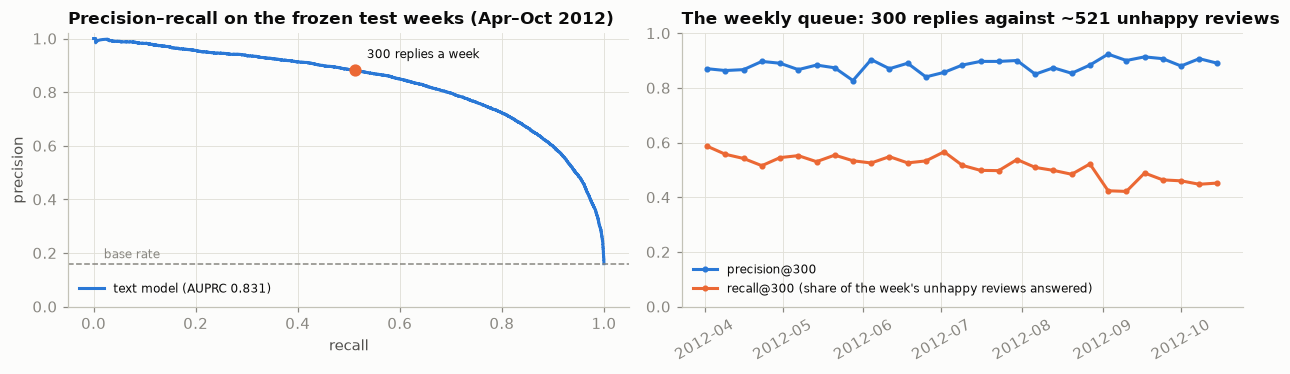

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
ax = axes[0]
pr, rc, _ = precision_recall_curve(y_all[te], s_te)
ax.plot(rc, pr, color=SERIES[0], lw=2, label=f"text model (AUPRC {average_precision_score(y_all[te], s_te):.3f})")
ax.axhline(y_all[te].mean(), color=MUTED, ls="--", lw=1); ax.text(0.02, y_all[te].mean() + 0.02, "base rate", color=MUTED, fontsize=8)
ax.plot([q_te["recall@k"].mean()], [q_te["precision@k"].mean()], "o", color=SERIES[1], ms=7)
ax.annotate(f"{REPLIES_PER_WEEK} replies a week", (q_te["recall@k"].mean(), q_te["precision@k"].mean()), xytext=(8, 8), textcoords="offset points", fontsize=8)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="lower left")
ax.set_title("Precision–recall on the frozen test weeks (Apr–Oct 2012)")
ax = axes[1]
t_ = q_te.index.start_time
ax.plot(t_, q_te["precision@k"], "-o", ms=3, lw=2, color=SERIES[0], label=f"precision@{REPLIES_PER_WEEK}")
ax.plot(t_, q_te["recall@k"], "-o", ms=3, lw=2, color=SERIES[1], label=f"recall@{REPLIES_PER_WEEK} (share of the week's unhappy reviews answered)")
ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="lower left"); ax.tick_params(axis="x", rotation=30)
ax.set_title(f"The weekly queue: {REPLIES_PER_WEEK} replies against ~{q_te.unhappy.mean():.0f} unhappy reviews")
plt.tight_layout(); plt.show()

**Reading this.** On the frozen test weeks AUPRC is 0.831 against a base rate of 0.160. 88.1 % of replies reach a 1–2-star review (82.7–92.3 % by week), covering 51.1 % of the ~521 unhappy reviews a week; recall slides from 0.55 to 0.46 across the weeks as unhappy reviews grow from 478 to 590 a week. 70 % of the misses are three-star reviews, which may deserve a reply anyway. Bigrams earn their place: *not good* pushes towards a reply, *not bad* away.

## 4 · The operating point: 300 replies a week

*Part B · Given model · the keyword rule `rule_score` is reference only; C3 asks you to own capacity and the precision floor.*

Capacity is the business constant (an assumption; task C3 varies it). What do 300 replies buy, and the next 100? The sweep answers on validation and test weeks, beside a keyword rule written in an afternoon.

,precision (valid),precision (test),recall (test),unhappy left unanswered a week (test),precision of the last 100 replies (test)
replies a week,,,,,
100,0.968,0.958,0.186,425,0.958
200,0.927,0.923,0.358,336,0.889
300,0.885,0.881,0.511,257,0.797
400,0.834,0.827,0.639,190,0.664
500,0.774,0.769,0.742,137,0.537
600,0.716,0.703,0.814,99,0.376
700,0.653,0.642,0.865,72,0.271
800,0.595,0.586,0.902,52,0.198


keyword rule at 300/week: precision 0.469, recall 0.272 · text model: precision 0.881, recall 0.511 · unhappy test reviews with no rule word: 60% · 4–5-star reviews in the rule's queue: 41% (model: 3.6%)
unhappy reviews a week, by year: {2007: 30, 2008: 46, 2009: 87, 2010: 156, 2011: 334, 2012: 521} → 300 replies would have covered every one up to 2010


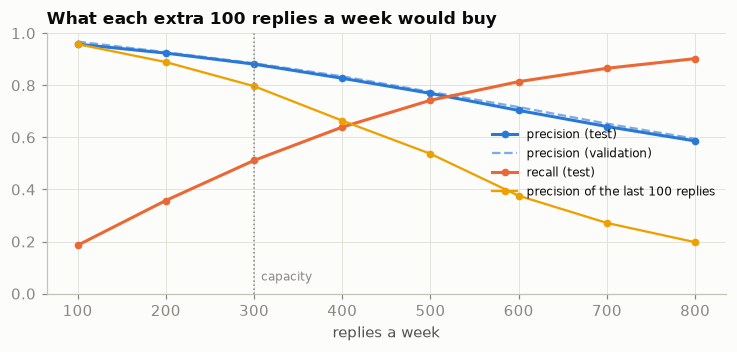

In [8]:
# A rule the team could write in an afternoon: count complaint words, longest review first on ties
COMPLAINT = re.compile(r"\b(disappoint\w*|terrible|awful|horrible|worst|stale|expired|rancid|broken|damaged|crushed|refund|return(?:ed)?|"
                       r"waste|never again|not worth|gross|threw (?:it|them) (?:out|away)|mold\w*|spoiled|sick)\b", re.I)
def rule_score(idx):
    t = rv.text.values[idx]
    return np.array([len(COMPLAINT.findall(x)) for x in t]) + np.array([len(x) for x in t]) / 1e5

q_rule = weekly_queue(te, rule_score(te), REPLIES_PER_WEEK)
caps = [100, 200, 300, 400, 500, 600, 700, 800]
sweep = []
for k in caps:
    qv, qt = weekly_queue(va, s_va, k), weekly_queue(te, s_te, k)
    sweep.append({"replies a week": k, "precision (valid)": qv["precision@k"].mean(), "precision (test)": qt["precision@k"].mean(),
                  "recall (test)": qt["recall@k"].mean(), "unhappy left unanswered a week (test)": (qt.unhappy * (1 - qt["recall@k"])).mean()})
sweep = pd.DataFrame(sweep).set_index("replies a week")
sweep["precision of the last 100 replies (test)"] = (sweep["precision (test)"] * sweep.index).diff() / pd.Series(sweep.index, index=sweep.index).diff()
sweep.loc[caps[0], "precision of the last 100 replies (test)"] = sweep.loc[caps[0], "precision (test)"]
display(sweep.style.format({c: "{:.3f}" for c in sweep.columns if "unanswered" not in c} | {"unhappy left unanswered a week (test)": "{:.0f}"}))
rs = rule_score(te)
print(f"keyword rule at {REPLIES_PER_WEEK}/week: precision {q_rule['precision@k'].mean():.3f}, recall {q_rule['recall@k'].mean():.3f} · "
      f"text model: precision {q_te['precision@k'].mean():.3f}, recall {q_te['recall@k'].mean():.3f} · unhappy test reviews with no rule word: "
      f"{(rs[y_all[te] == 1] < 1).mean():.0%} · 4–5-star reviews in the rule's queue: {q_rule[['4★', '5★']].sum(axis=1).mean():.0%} (model: {q_te[['4★', '5★']].sum(axis=1).mean():.1%})")
neg_per_week = rv[(rv.date >= "2007-01-01") & (rv.date < TEST_END)].groupby(rv.date.dt.year).y.sum() / 52
neg_per_week[2012] = q_te.unhappy.mean()
print("unhappy reviews a week, by year:", {k: int(v) for k, v in neg_per_week.round().items()},
      f"→ {REPLIES_PER_WEEK} replies would have covered every one up to {neg_per_week[neg_per_week <= REPLIES_PER_WEEK].index.max()}")

fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.plot(sweep.index, sweep["precision (test)"], "-o", ms=4, lw=2, color=SERIES[0], label="precision (test)")
ax.plot(sweep.index, sweep["precision (valid)"], "--", lw=1.5, color=SERIES[0], alpha=0.6, label="precision (validation)")
ax.plot(sweep.index, sweep["recall (test)"], "-o", ms=4, lw=2, color=SERIES[1], label="recall (test)")
ax.plot(sweep.index, sweep["precision of the last 100 replies (test)"], "-o", ms=4, lw=1.5, color=SERIES[3], label="precision of the last 100 replies")
ax.axvline(REPLIES_PER_WEEK, color=MUTED, ls=":", lw=1); ax.text(REPLIES_PER_WEEK + 8, 0.05, "capacity", color=MUTED, fontsize=8)
ax.set_xlabel("replies a week"); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="center right")
ax.set_title("What each extra 100 replies a week would buy")
plt.tight_layout(); plt.show()

The operating point is stable: precision 0.885 at 300 on validation, 0.881 on test. The rule reaches 0.469: 60 % of unhappy reviews use none of its words, and 41 % of its queue is 4–5-star reviews (model: 3.6 %). The marginal column is the hiring argument: replies 201–300 still reach an unhappy reviewer 80 % of the time, 301–400 66 %, 501–600 38 %. And the backlog grows: 30 unhappy reviews a week in 2007, 156 in 2010, 521 in 2012; 300 replies covered them all until 2010 and half now. The ADR (task C3) records the capacity and the precision floor below which a reply is not worth writing.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

**Trap 1 — one review, many pages.** The same review appears on every variant of a listing, so 30.8 % of rows copy another. A random split puts copies on both sides.

In [9]:
# Trap 1 — copies. Same reviews, two random splits: page rows (copies on both sides) vs distinct reviews
in_scope = np.isin(pages.rid.values, need[(rv.date.values[need] >= TRAIN_START) & (rv.date.values[need] < TEST_END)])
rows = pages[in_scope][["rid"]].reset_index(drop=True)
n_fit, n_eval = N_TRAIN, 40_000
a = rng.choice(len(rows), n_fit + n_eval, replace=False); a_tr, a_te = a[:n_fit], a[n_fit:]
f_rows = fit_text_model(rows.rid.values[a_tr], ALPHA)
s_rows = f_rows(rows.rid.values[a_te]); y_rows = y_all[rows.rid.values[a_te]]
seen = np.isin(rows.rid.values[a_te], rows.rid.values[a_tr])
pool_d = np.unique(rows.rid.values)
b = rng.choice(pool_d, n_fit + n_eval, replace=False)
f_dist = fit_text_model(b[:n_fit], ALPHA); s_dist = f_dist(b[n_fit:])
trap1 = pd.DataFrame([
    {"split": "random, page rows (copies kept) ⚠", "AUPRC": average_precision_score(y_rows, s_rows), "ROC-AUC": roc_auc_score(y_rows, s_rows)},
    {"split": "random, distinct reviews", "AUPRC": average_precision_score(y_all[b[n_fit:]], s_dist), "ROC-AUC": roc_auc_score(y_all[b[n_fit:]], s_dist)},
    {"split": "forward in time, distinct reviews (Section 3)", "AUPRC": average_precision_score(y_all[te], s_te), "ROC-AUC": roc_auc_score(y_all[te], s_te)},
]).set_index("split")
display(trap1.style.format("{:.3f}"))
print(f"{len(rows):,} page rows hold {len(pool_d):,} distinct reviews · {seen.mean():.1%} of the random test rows have their text in training: "
      f"AUPRC {average_precision_score(y_rows[seen], s_rows[seen]):.3f} on those vs {average_precision_score(y_rows[~seen], s_rows[~seen]):.3f} on the rest")

# The queue built on page rows: the same review fills several reply slots
pr_te = pages[np.isin(pages.rid.values, te)].copy()
pr_te["s"] = pd.Series(s_te, index=te).reindex(pr_te.rid.values).values
pr_te["y"] = y_all[pr_te.rid.values]
pr_te["week"] = pr_te.date.dt.to_period("W")
naive_q = pr_te.groupby("week").apply(lambda g: pd.Series({"precision on rows": g.nlargest(REPLIES_PER_WEEK, "s").y.mean(),
                                                          "distinct reviews answered": g.nlargest(REPLIES_PER_WEEK, "s").rid.nunique()}), include_groups=False)
print(f"queue on page rows: reported precision@{REPLIES_PER_WEEK} {naive_q['precision on rows'].mean():.3f}, but only "
      f"{naive_q['distinct reviews answered'].mean():.0f} distinct reviews answered a week ({1 - naive_q['distinct reviews answered'].mean() / REPLIES_PER_WEEK:.0%} of replies are repeats) · "
      f"queue on distinct reviews: precision {q_te['precision@k'].mean():.3f}, {REPLIES_PER_WEEK} reviews answered")

,AUPRC,ROC-AUC
split,,
"random, page rows (copies kept) ⚠",0.891,0.973
"random, distinct reviews",0.834,0.960
"forward in time, distinct reviews (Section 3)",0.831,0.957


339,958 page rows hold 235,822 distinct reviews · 27.9% of the random test rows have their text in training: AUPRC 0.998 on those vs 0.827 on the rest
queue on page rows: reported precision@300 0.887, but only 210 distinct reviews answered a week (30% of replies are repeats) · queue on distinct reviews: precision 0.881, 300 reviews answered


The random split on page rows reports 0.891 AUPRC: 27.9 % of its test rows have their text in training and score 0.998. Merged first, the same split gives 0.834; forward in time, 0.831. Copies also break the queue: a review on five pages fills five reply slots. Ranked on page rows, the queue reports 0.887 precision but answers only 210 distinct reviews a week; 30 % of replies are repeats. Merge before any split, as a tested data contract (task C1).

**Trap 2 — votes arrive after the review.** Helpfulness votes are counted on the crawl day: 72 % of 2008 reviews had one by then, 34 % of 2012 ones. Readers vote unhappy reviews down (55 % of a one-star review's votes say "helpful" on average, 88 % of a five-star one's), so votes carry the label.

In [10]:
# Trap 2 — helpfulness votes are counted at the crawl (Oct 2012), not when the review is posted
def votes(idx, at_posting=False):
    yes, tot = rv.helpful_yes.values[idx].astype(float), rv.helpful_votes.values[idx].astype(float)
    if at_posting:                                    # what the scorer sees on the day the review arrives
        yes, tot = 0 * yes, 0 * tot
    ratio = np.where(tot > 0, yes / np.maximum(tot, 1), 0.5)
    return sp.csr_matrix(np.c_[np.log1p(yes), np.log1p(tot), np.log1p(tot - yes), ratio, tot > 0].astype(np.float32))

f_votes = fit_text_model(tr, ALPHA, extra=votes)
s_v_crawl, s_v_post = f_votes(te), f_votes(te, extra_fn=lambda j: votes(j, at_posting=True))
# the same experiment on older reviews whose votes had a year or more to accumulate: the 2010–2011 sample split forward, 80/20
o_tr, o_te = tr[: int(0.8 * len(tr))], tr[int(0.8 * len(tr)):]
old_span = f"{rv.date.values[o_te].min().astype('datetime64[D]')} → {rv.date.values[o_te].max().astype('datetime64[D]')}"
f_old_t, f_old_v = fit_text_model(o_tr, ALPHA), fit_text_model(o_tr, ALPHA, extra=votes)
v_only = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=50, tol=None, random_state=SEED, n_jobs=N_JOBS).fit(votes(o_tr), y_all[o_tr])
trap2 = pd.DataFrame([
    {"evaluation": "older reviews, votes alone ⚠ (base rate %.3f)" % y_all[o_te].mean(), "AUPRC": average_precision_score(y_all[o_te], v_only.decision_function(votes(o_te)))},
    {"evaluation": "2012 test, votes alone at the crawl (base rate %.3f)" % y_all[te].mean(), "AUPRC": average_precision_score(y_all[te], v_only.decision_function(votes(te)))},
    {"evaluation": "2012 test, text only (honest)", "AUPRC": average_precision_score(y_all[te], s_te)},
    {"evaluation": "2012 test, text + votes counted at the crawl ⚠", "AUPRC": average_precision_score(y_all[te], s_v_crawl)},
    {"evaluation": "2012 test, text + votes as on the posting day (zero)", "AUPRC": average_precision_score(y_all[te], s_v_post)},
    {"evaluation": "older reviews, text only", "AUPRC": average_precision_score(y_all[o_te], f_old_t(o_te))},
    {"evaluation": "older reviews, text + votes at the crawl ⚠", "AUPRC": average_precision_score(y_all[o_te], f_old_v(o_te))},
]).set_index("evaluation")
display(trap2.style.format("{:.3f}"))
hr = rv[rv.helpful_votes > 0]
print(f"'older reviews' = trained on the first 80 % of the 2010–2011 sample, tested on the last 20 % ({old_span})")
print("share of 'helpful' among votes, by star:", (hr.helpful_yes / hr.helpful_votes).groupby(hr.score).mean().round(2).to_dict(),
      "· reviews with ≥ 1 vote at the crawl, by posting year:", rv[rv.year >= 2008].groupby("year").helpful_votes.apply(lambda s: f"{(s > 0).mean():.0%}").to_dict())

,AUPRC
evaluation,
"older reviews, votes alone ⚠ (base rate 0.161)",0.400
"2012 test, votes alone at the crawl (base rate 0.160)",0.301
"2012 test, text only (honest)",0.831
"2012 test, text + votes counted at the crawl ⚠",0.830
"2012 test, text + votes as on the posting day (zero)",0.824
"older reviews, text only",0.833
"older reviews, text + votes at the crawl ⚠",0.836


'older reviews' = trained on the first 80 % of the 2010–2011 sample, tested on the last 20 % (2011-10-07 → 2012-01-01)


share of 'helpful' among votes, by star: {1: 0.55, 2: 0.59, 3: 0.64, 4: 0.8, 5: 0.88} · reviews with ≥ 1 vote at the crawl, by posting year: {2008: '72%', 2009: '69%', 2010: '66%', 2011: '56%', 2012: '34%'}


On older reviews (7 Oct 2011 – 1 Jan 2012) votes alone reach 0.400 AUPRC against a base rate of 0.161, and adding them to the text looks like a gain (0.833 → 0.836). But the scorer sees a review on its first day, with no votes; that model then scores 0.824 on 2012, below text alone (0.831). The offline gain is a leak; the online loss is real.

**Trap 3 — the title is the verdict.** It is typed on the same form as the star: 3,677 titles say *awful*, *terrible*, *horrible* or *worst*, and 89 % of them carry 1–2 stars.

In [11]:
# Trap 3 — the summary line (the review's title) is the reviewer's verdict in words
hs = HashingVectorizer(ngram_range=(1, 2), n_features=2 ** 18, alternate_sign=False, norm=None, dtype=np.float32)
S_tr, S_te = hs.transform(rv.summary.values[tr]), hs.transform(rv.summary.values[te])
tfs = TfidfTransformer(sublinear_tf=True).fit(S_tr)
summary_feats = lambda j, blank=False: tfs.transform(hs.transform(rv.summary.values[j])) * (0.0 if blank else 1.0)
f_sum_only = SGDClassifier(loss="log_loss", alpha=ALPHA, max_iter=20, tol=None, random_state=SEED, n_jobs=N_JOBS).fit(tfs.transform(S_tr), y_all[tr])
f_both = fit_text_model(tr, ALPHA, extra=summary_feats)
s_b, s_b0 = f_both(te), f_both(te, extra_fn=lambda j: summary_feats(j, blank=True))
s_so = f_sum_only.decision_function(tfs.transform(S_te))
trap3 = pd.DataFrame([
    {"inputs": "review text only (honest)", "AUPRC": average_precision_score(y_all[te], s_te), f"precision@{REPLIES_PER_WEEK}": q_te["precision@k"].mean()},
    {"inputs": "summary line only", "AUPRC": average_precision_score(y_all[te], s_so), f"precision@{REPLIES_PER_WEEK}": weekly_queue(te, s_so, REPLIES_PER_WEEK)["precision@k"].mean()},
    {"inputs": "text + summary line ⚠", "AUPRC": average_precision_score(y_all[te], s_b), f"precision@{REPLIES_PER_WEEK}": weekly_queue(te, s_b, REPLIES_PER_WEEK)["precision@k"].mean()},
    {"inputs": "text + summary model, served on text without a title", "AUPRC": average_precision_score(y_all[te], s_b0), f"precision@{REPLIES_PER_WEEK}": weekly_queue(te, s_b0, REPLIES_PER_WEEK)["precision@k"].mean()},
]).set_index("inputs")
display(trap3.style.format("{:.3f}"))
verdict = rv.summary.str.contains(r"\b(?:awful|terrible|horrible|worst)\b", case=False, regex=True)
print(f"summary lines with 'awful/terrible/horrible/worst': {verdict.sum():,}, of which {rv.y[verdict].mean():.0%} carry 1–2 stars")

,AUPRC,precision@300
inputs,,
review text only (honest),0.831,0.881
summary line only,0.760,0.819
text + summary line ⚠,0.873,0.908
"text + summary model, served on text without a title",0.813,0.870


summary lines with 'awful/terrible/horrible/worst': 3,677, of which 89% carry 1–2 stars


Text plus title scores 0.873 (precision@300 0.908) against 0.831 (0.881) for text alone; the title alone reaches 0.760. But the scorer is meant for channels without a title, and served there the same model drops to 0.813, below text alone. Train on what you serve; where a title exists, so does the star.

**Trap 4 — five stars and the neutral middle.** Three tutorial habits inflate the numbers: accuracy, dropping three-star reviews, balanced test sets.

In [12]:
# Trap 4 — the five-star skew and the neutral middle
p_te = triage.model.predict_proba(triage.tfidf.transform(H(te)))[:, 1]
yt = y_all[te]
not3 = rv.score.values[te] != 3
pos_i = np.flatnonzero(yt == 1)
bal = np.r_[pos_i, rng.choice(np.flatnonzero(yt == 0), len(pos_i), replace=False)]
keep = rv.score.values[tr] != 3
f_no3 = fit_text_model(tr[keep], ALPHA)
trap4 = pd.DataFrame([
    {"evaluation": "always answer 'no reply needed'", "metric": "accuracy", "value": 1 - yt.mean()},
    {"evaluation": "text model at a 0.5 threshold", "metric": "accuracy", "value": accuracy_score(yt, p_te >= 0.5)},
    {"evaluation": "text model at a 0.5 threshold", "metric": "recall", "value": (p_te[yt == 1] >= 0.5).mean()},
    {"evaluation": "all test reviews (honest)", "metric": "AUPRC", "value": average_precision_score(yt, s_te)},
    {"evaluation": "3-star reviews dropped from the test ⚠", "metric": "AUPRC", "value": average_precision_score(yt[not3], s_te[not3])},
    {"evaluation": "balanced 50/50 test sample ⚠", "metric": "AUPRC", "value": average_precision_score(yt[bal], s_te[bal])},
    {"evaluation": "balanced 50/50 test sample ⚠", "metric": "precision at 0.5", "value": yt[bal][p_te[bal] >= 0.5].mean()},
    {"evaluation": "real prevalence (honest)", "metric": "precision at 0.5", "value": yt[p_te >= 0.5].mean()},
    {"evaluation": "trained without 3-star reviews, all test reviews", "metric": "AUPRC", "value": average_precision_score(yt, f_no3(te))},
]).set_index(["evaluation", "metric"])
display(trap4.style.format("{:.3f}"))

"Never reply" is 84.0 % accurate; the model at 0.5 is 91.9 % accurate and still misses 40 % of unhappy reviews. Dropping three-star reviews from the test lifts AUPRC from 0.831 to 0.904; a balanced test lifts it to 0.954, and precision at 0.5 from 0.849 to 0.969. Neither is the team's queue. Training without three-star reviews costs 0.021 AUPRC on the real mix.

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · What customers are saying, and how it drifts over thirteen years

*Part C · Productionise · the drift your monitoring plan must catch (C5); package the given topic digest, which E4 labels by hand.*

Three drifts are built in: **volume**, **prevalence** (10 % → 16 % unhappy), and **vocabulary and product mix**. First the classifier, frozen on 2007–08, against a model retrained on the two years before each year.

In [13]:
# 6a · The frozen classifier: trained on 2007–2008, scored on each later year; against a model retrained on the two years before
frozen_idx = np.concatenate([drift[y_] for y_ in FROZEN_YEARS])
frozen = fit_text_model(frozen_idx, ALPHA)
seen_cols = np.unique(H(frozen_idx).indices)
per_year = []
for yr in range(FROZEN_YEARS[-1] + 1, 2013):
    j = drift[yr]
    retrained = frozen if yr - 2 in FROZEN_YEARS and yr - 1 in FROZEN_YEARS else fit_text_model(np.r_[drift[yr - 2], drift[yr - 1]], ALPHA)
    s_f, s_r = frozen(j), retrained(j)
    Hj = H(j)
    per_year.append({"year": yr, "1–2-star share": y_all[j].mean(),
                     "AUPRC frozen": average_precision_score(y_all[j], s_f), "AUPRC retrained": average_precision_score(y_all[j], s_r),
                     "ROC-AUC frozen": roc_auc_score(y_all[j], s_f), "ROC-AUC retrained": roc_auc_score(y_all[j], s_r),
                     "n-gram mass unseen by the frozen model": Hj.data[~np.isin(Hj.indices, seen_cols)].sum() / Hj.data.sum()})
per_year = pd.DataFrame(per_year).set_index("year")
display(per_year.style.format("{:.3f}", na_rep="–"))

,1–2-star share,AUPRC frozen,AUPRC retrained,ROC-AUC frozen,ROC-AUC retrained,n-gram mass unseen by the frozen model
year,,,,,,
2009,0.121,0.716,0.716,0.938,0.938,0.059
2010,0.142,0.744,0.753,0.941,0.942,0.062
2011,0.153,0.773,0.786,0.946,0.948,0.062
2012,0.155,0.785,0.801,0.948,0.952,0.063


The frozen model's AUPRC *rises* from 0.716 to 0.785 because the base rate rises (12.1 % → 15.5 %): AUPRC is not comparable across years with different prevalence. Against the retrained model it falls behind by 0.016 by 2012 (0.785 against 0.801); ROC-AUC, which ignores prevalence, agrees (0.948 against 0.952). The language of unhappiness is stable: 5.9–6.3 % of each later year's n-gram mass is unseen in training. For the queue, the drift that matters is volume.

Next, **topics**: non-negative matrix factorisation (NMF) of word counts, fitted on 2010–2011, with generic praise and complaint words removed. A review whose largest topic weight is below the training 5th percentile has "no clear topic".

In [14]:
# 6b · Topics: NMF fitted on 2010–2011 reviews only; aspect words, with generic praise and complaint words removed
GENERIC = set("""great good love loved like liked best delicious excellent yummy awesome tasty product products favorite nice wonderful perfect
amazing really just yum stuff taste tastes tasted tasting flavor flavors flavour flavorful highly recommend recommended fantastic better
bad terrible awful worst disappointed disappointing horrible poor ok okay pretty little lot bit don didn doesn isn wasn ve ll make
makes made use used using try tried buy bought get got think know way time times thing things want really definitely""".split())
month_now = rv.index[(rv.date >= "2012-10-01")].values
prev12 = rv.index[(rv.date >= "2011-10-01") & (rv.date < "2012-10-01")].values
prev12 = np.sort(rng.choice(prev12, DRIFT_PER_YEAR, replace=False))
topic_rows = np.unique(np.concatenate(list(drift.values()) + [month_now, prev12]))
t0 = time.time()
cv_t = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | GENERIC), min_df=20, max_df=0.3, max_features=6000, token_pattern=r"(?u)\b[a-z][a-z\-]+\b")
C = cv_t.fit_transform(rv.text.values[topic_rows]).tocsr()
crow = pd.Series(np.arange(len(topic_rows)), index=topic_rows)
fit_rows = np.r_[drift[2010], drift[2011]]
tft = TfidfTransformer(sublinear_tf=True).fit(C[crow[fit_rows].values])
nmf = NMF(n_components=N_TOPICS, init="nndsvda", random_state=SEED, max_iter=300).fit(tft.transform(C[crow[fit_rows].values]))
vocab_t = cv_t.get_feature_names_out()
topic_name = [" · ".join(vocab_t[np.argsort(-c)[:3]]) for c in nmf.components_]
Wt = nmf.transform(tft.transform(C))
weak = np.quantile(Wt[crow[fit_rows].values].max(1), 0.05)             # 5 % of training reviews fit no topic well
topic = np.where(Wt.max(1) < weak, -1, Wt.argmax(1))
topic_of = pd.Series(topic, index=topic_rows)
print(f"topics fitted in {time.time()-t0:.0f}s on {len(fit_rows):,} reviews (2010–2011); 'no clear topic' = max weight below the training 5th percentile")
for k, nm in enumerate(topic_name):
    print(f"  T{k:<2d} {nm:38s} · {', '.join(vocab_t[np.argsort(-nmf.components_[k])[3:8]])}")
yr_rows = {yr: drift[yr] for yr in range(2007, 2013)}
shares = pd.DataFrame({yr: pd.Series(topic_of[j].values).value_counts(normalize=True) for yr, j in yr_rows.items()}).T.fillna(0)
shares.columns = ["no clear topic" if c == -1 else f"T{c} {topic_name[c]}" for c in shares.columns]
print("share of each year's reviews with no clear topic:", {yr: f"{v:.1%}" for yr, v in shares["no clear topic"].items()})
moved = (shares.loc[2012] - shares.loc[2007]).drop("no clear topic").sort_values()
print("largest moves 2007 → 2012 (points):", ", ".join(f"{k} {v * 100:+.1f}" for k, v in pd.concat([moved.head(2), moved.tail(2)]).items()))

topics fitted in 7s on 30,000 reviews (2010–2011); 'no clear topic' = max weight below the training 5th percentile
  T0  snack · eat · healthy                  · bars, cereal, butter, peanut, sweet
  T1  coffee · cup · strong                  · roast, bitter, bold, blend, starbucks
  T2  tea · green · teas                     · iced, bags, black, cup, drink
  T3  amazon · store · stores                · grocery, local, cheaper, available, com
  T4  dog · dogs · treats                    · loves, treat, teeth, chew, small
  T5  chocolate · dark · cookies             · hot, bar, milk, cookie, cocoa
  T6  order · ordered · box                  · arrived, received, gift, item, came
  T7  sauce · hot · salt                     · oil, add, chicken, soup, rice
  T8  food · cat · cats                      · eat, dry, foods, baby, canned
  T9  free · gluten · bread                  · mix, cookies, flour, shipping, wheat
  T10 price · quality · shipping             · worth, reasonable, beat, sav

In [15]:
# 6c · "This month": October 2012 (1–26) against the twelve months before
now_t, prev_t = topic_of[month_now].values, topic_of[prev12].values
digest = pd.DataFrame({"share this month": pd.Series(now_t).value_counts(normalize=True),
                       "share, previous 12 months": pd.Series(prev_t).value_counts(normalize=True),
                       "1–2-star share this month": pd.Series(y_all[month_now]).groupby(now_t).mean(),
                       "reviews this month": pd.Series(now_t).value_counts()}).fillna(0)
digest["change (points)"] = (digest["share this month"] - digest["share, previous 12 months"]) * 100
digest.index = ["no clear topic" if c == -1 else f"T{c} {topic_name[c]}" for c in digest.index]
digest = digest.sort_values("reviews this month", ascending=False)
display(digest.style.format({"share this month": "{:.1%}", "share, previous 12 months": "{:.1%}", "1–2-star share this month": "{:.1%}",
                             "reviews this month": "{:,.0f}", "change (points)": "{:+.1f}"}))
# rising words: document frequency this month vs the previous 12 months (smoothed log ratio, ≥ 0.5 % of this month's reviews)
df_now = np.asarray((C[crow[month_now].values] > 0).mean(0)).ravel()
df_prev = np.asarray((C[crow[prev12].values] > 0).mean(0)).ravel()
lr = np.log((df_now + 1e-3) / (df_prev + 1e-3))
ok = df_now >= 0.005
rising = pd.DataFrame({"this month": df_now, "previous 12 months": df_prev, "ratio": np.exp(lr)}, index=vocab_t)[ok].sort_values("ratio", ascending=False).head(10)
print(f"October 2012: {len(month_now):,} distinct reviews, {y_all[month_now].mean():.1%} with 1–2 stars (previous 12 months: {y_all[prev12].mean():.1%})")
print("rising words this month:", ", ".join(f"{w_} ×{r_:.1f}" for w_, r_ in rising.ratio.items()))
long_rise = pd.DataFrame({yr: np.asarray((C[crow[drift[yr]].values] > 0).mean(0)).ravel() for yr in range(2007, 2013)}, index=vocab_t)
lr_long = ((long_rise[2012] + 1e-3) / (long_rise[[2007, 2008]].mean(axis=1) + 1e-3))[long_rise[2012] >= 0.005].sort_values(ascending=False)
print("rising words 2012 vs 2007–08:", ", ".join(f"{w_} ×{r_:.0f}" for w_, r_ in lr_long.head(10).items()))
print("falling words 2012 vs 2007–08:", ", ".join(f"{w_} ×{r_:.2f}" for w_, r_ in lr_long.sort_values().head(6).items()))
shampoo = rv.text.str.contains("shampoo", case=False, regex=False)
top_l = rv.listing[shampoo].value_counts().index[0]
in_l = rv.listing == top_l
print(f"reviews mentioning shampoo: {shampoo.sum():,}; the largest such listing has {sizes[top_l]} product ids and {in_l.sum():,} reviews, "
      f"{rv.year[in_l].value_counts().to_dict()} by year, {shampoo[in_l].mean():.0%} of them mention shampoo · its topic: "
      f"{pd.Series(topic_of.reindex(rv.index[in_l & rv.index.isin(topic_rows)]).values).map(lambda c: 'no clear topic' if c == -1 else topic_name[int(c)]).value_counts(normalize=True).head(2).round(2).to_dict()}")

,share this month,"share, previous 12 months",1–2-star share this month,reviews this month,change (points)
T6 order · ordered · box,17.2%,17.1%,24.8%,"2,502",+0.1
T7 sauce · hot · salt,11.7%,11.0%,10.8%,"1,699",+0.6
T11 sugar · drink · water,10.9%,13.2%,15.6%,"1,581",-2.4
T1 coffee · cup · strong,10.6%,8.9%,12.0%,"1,548",+1.7
T2 tea · green · teas,6.7%,6.2%,10.2%,974,+0.5
T3 amazon · store · stores,6.7%,6.9%,10.6%,971,-0.2
T4 dog · dogs · treats,6.4%,6.5%,12.8%,927,-0.1
no clear topic,6.3%,5.3%,18.1%,914,+1.0
T8 food · cat · cats,6.2%,6.0%,16.8%,904,+0.2
T10 price · quality · shipping,5.7%,5.2%,12.1%,826,+0.5


October 2012: 14,548 distinct reviews, 15.0% with 1–2 stars (previous 12 months: 15.9%)
rising words this month: blackberry ×3.2, lipton ×1.8, herbal ×1.8, pasta ×1.6, teaspoon ×1.5, pumpkin ×1.5, san ×1.5, bed ×1.4, prepared ×1.4, microwave ×1.4
rising words 2012 vs 2007–08: shampoo ×8, scalp ×8, conditioner ×7, hair ×6, subscribe ×3, quaker ×3, k-cups ×3, keurig ×3, prime ×3, issues ×3
falling words 2012 vs 2007–08: wheat ×0.59, cereal ×0.64, children ×0.66, fun ×0.66, salad ×0.68, teas ×0.69


reviews mentioning shampoo: 1,474; the largest such listing has 17 product ids and 1,656 reviews, {2012: 1656} by year, 72% of them mention shampoo · its topic: {'no clear topic': 0.31, 'sugar · drink · water': 0.24}


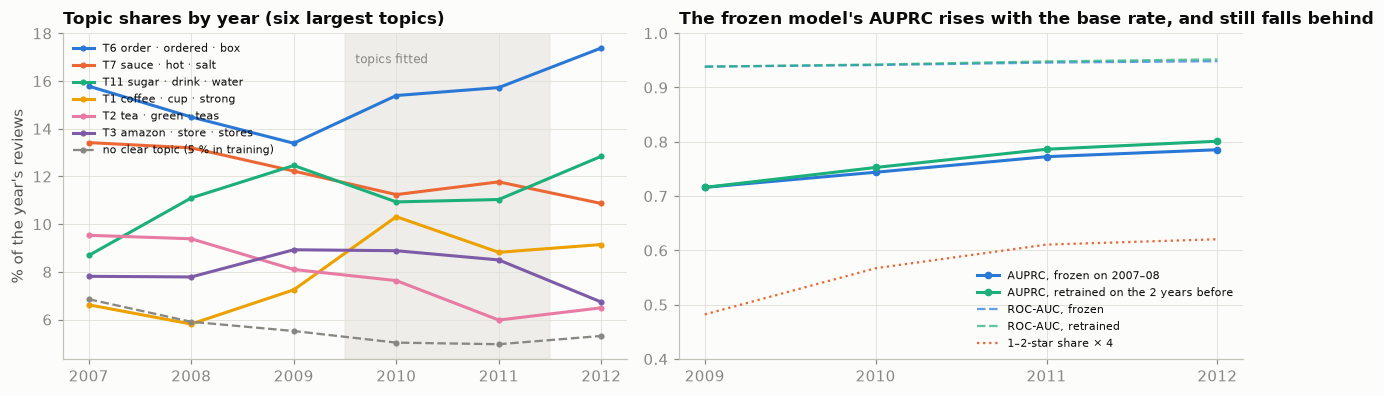

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
ax = axes[0]
top_cols = shares.drop(columns="no clear topic").max().sort_values(ascending=False).index[:6]
for c, color in zip(top_cols, SERIES + ["#e87ba4", "#7d5ba6"]):
    ax.plot(shares.index, shares[c] * 100, "-o", ms=3, lw=2, color=color, label=c)
ax.plot(shares.index, shares["no clear topic"] * 100, "--o", ms=3, lw=1.5, color=MUTED, label="no clear topic (5 % in training)")
ax.axvspan(2009.5, 2011.5, color=GRID, alpha=0.5); ax.text(2009.6, ax.get_ylim()[1] * 0.93, "topics fitted", color=MUTED, fontsize=8)
ax.set_ylabel("% of the year's reviews"); ax.legend(fontsize=7, loc="upper left", ncol=1)
ax.set_title("Topic shares by year (six largest topics)")
ax = axes[1]
ax.plot(per_year.index, per_year["AUPRC frozen"], "-o", ms=4, lw=2, color=SERIES[0], label="AUPRC, frozen on 2007–08")
ax.plot(per_year.index, per_year["AUPRC retrained"], "-o", ms=4, lw=2, color=SERIES[2], label="AUPRC, retrained on the 2 years before")
ax.plot(per_year.index, per_year["ROC-AUC frozen"], "--", lw=1.5, color=SERIES[0], alpha=0.7, label="ROC-AUC, frozen")
ax.plot(per_year.index, per_year["ROC-AUC retrained"], "--", lw=1.5, color=SERIES[2], alpha=0.7, label="ROC-AUC, retrained")
ax.plot(per_year.index, per_year["1–2-star share"] * 4, ":", lw=1.5, color=SERIES[1], label="1–2-star share × 4")
ax.set_xticks(per_year.index); ax.legend(fontsize=7, loc="lower right"); ax.set_ylim(0.4, 1)
ax.set_title("The frozen model's AUPRC rises with the base rate, and still falls behind")
plt.tight_layout(); plt.show()

**This month.** October 2012 (to the 26th) has 14,548 reviews, 15.0 % unhappy. The order-and-delivery topic (T6: *order, ordered, box, arrived, received, gift*) is the largest at 17 % and the most negative: 24.8 % of its reviews carry 1–2 stars, the customer team's own territory. Coffee is up 1.7 points on the previous twelve months; drinks and sweeteners are down 2.4. Rising words (*blackberry*, *Lipton*, *herbal*, *pumpkin*) are seasonality and single-product bursts: a list for a person, not an alarm.

**Thirteen years.** Since 2007 tea lost 3.0 points and drinks and sweeteners gained 4.2. The words that rose most are *shampoo, scalp, conditioner, hair* (×6–8): one listing, 17 product ids and 1,656 reviews, all from 2012. Then *subscribe*, *prime*, *k-cups*, *keurig*: subscriptions and single-serve coffee arrived. Topics fitted on 2010–2011 have no place for shampoo: 31 % of that listing's reviews have no clear topic, 24 % land in *sugar · drink · water*. Yet the overall "no clear topic" share barely moves (5.0 % in 2011, 5.3 % in 2012), because one listing is 1 % of a year. Monitor topic fit per listing.

## 7 · Product summaries with citations, and the product graph

*Part C · Productionise · package the given summariser and graph rules (Part B material, kept here for contiguity); E1 relabels the ablation, S1 extends `generate`.*

The baseline summarises **extractively**: split a product page's reviews into sentences and pick three from 4–5-star and two from 1–2-star reviews by **maximal marginal relevance** (MMR: close to the pool's centroid, far from sentences already chosen). Sentences are verbatim and cite their review id: a summary cannot invent, only choose badly.

**The golden set.** Products with at least 40 distinct reviews on their page since January 2012: 595 pages in 200 listings; 60 sampled, one per listing so no pool is scored twice. The reference is independent of the summariser: the reviewers' own titles (Trap 3's leak, turned into a gift). Per product, up to eight aspect words (generic praise and complaint removed) found in at least 5 % of its titles; **aspect recall** is the share the summary mentions. λ = 0.7 and the 3 + 2 split were fixed before scoring.

In [17]:
# 7a · Extractive summaries: sentences from the product page's reviews, chosen by centrality minus redundancy (MMR)
win = rv.index[rv.date >= SUMMARY_START].values
page_pool = pages[np.isin(pages.rid.values, win)].drop_duplicates(["product_id", "rid"])
page_n = page_pool.groupby("product_id").size()
eligible = page_n[page_n >= MIN_REVIEWS_GOLD].rename("reviews").reset_index().rename(columns={"index": "product_id"})
eligible["listing"] = eligible.product_id.map(listing_of)
one_per_listing = eligible.sort_values(["reviews", "product_id"], ascending=[False, True]).drop_duplicates("listing")
pool_of = page_pool.groupby("product_id").rid.apply(np.array)

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")
def sentences(rids):
    out = []
    for r in rids:
        for s_ in SENT_SPLIT.split(rv.text.values[r]):
            n = len(s_.split())
            if 6 <= n <= 40 and "http" not in s_:
                out.append((int(rv.review_id.values[r]), s_))
    return out

def mmr(sents, k, lam=0.7, allowed=None):
    '''Maximal marginal relevance over TF-IDF sentence vectors: close to the pool's centroid, far from what is already chosen.'''
    if not sents or k <= 0:
        return []
    V = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit_transform([s_ for _, s_ in sents])
    cen = np.asarray(V.mean(0)).ravel(); cen /= np.linalg.norm(cen) + 1e-9
    rel = V @ cen
    ok = np.ones(len(sents), bool) if allowed is None else np.array([allowed(s_) for _, s_ in sents])
    chosen = []
    for _ in range(k):
        cand_ = [j for j in np.flatnonzero(ok) if j not in chosen]
        if not cand_:
            break
        red = (V[cand_] @ V[chosen].T).toarray().max(1) if chosen else np.zeros(len(cand_))
        chosen.append(cand_[int(np.argmax(lam * rel[cand_] - (1 - lam) * red))])
    return [(sents[j][0], sents[j][1], float(rel[j])) for j in chosen]

def summarise(pid, allowed=None):
    rids = pool_of[pid]
    sc = rv.score.values[rids]
    return mmr(sentences(rids[sc >= 4]), K_POS, allowed=allowed) + mmr(sentences(rids[sc <= 2]), K_NEG, allowed=allowed)

def latest_reviews(pid, k=K_POS + K_NEG):
    '''What a dashboard shows by default: the first sentence of the newest reviews.'''
    rids = pool_of[pid]
    rids = rids[np.argsort(-rv.date.values[rids].astype("int64"), kind="stable")]
    out = []
    for r in rids:
        s_ = sentences([r])
        if s_:
            out.append((*s_[0], 0.0))
        if len(out) == k:
            break
    return out

# The golden set: reviewers' own summary lines are a free reference the summariser never reads
TOK = lambda s_: [t for t in re.findall(r"[a-z][a-z'\-]+", s_.lower()) if t not in ENGLISH_STOP_WORDS and t not in GENERIC and len(t) > 2]
def aspect_reference(pid, top=8, min_share=0.05):
    rids = pool_of[pid]
    c = Counter(t for r in rids for t in set(TOK(rv.summary.values[r])))
    return [w_ for w_, v in c.most_common(top) if v / len(rids) >= min_share]
def aspect_recall(summary, ref):
    got = {t for _, s_, _ in summary for t in TOK(s_)}
    return np.mean([r in got for r in ref]) if ref else np.nan

gold = one_per_listing.sample(N_GOLD, random_state=SEED).product_id.tolist()
gold_ref = {p: aspect_reference(p) for p in gold}
print(f"{len(eligible):,} product pages with ≥ {MIN_REVIEWS_GOLD} distinct reviews since {SUMMARY_START:%b %Y}, in {len(one_per_listing):,} listings · "
      f"golden set: {N_GOLD} products, one per listing, {np.mean([len(v) for v in gold_ref.values()]):.1f} reference aspect words each "
      f"(from {sum(len(pool_of[p]) for p in gold):,} summary lines)")

595 product pages with ≥ 40 distinct reviews since Jan 2012, in 200 listings · golden set: 60 products, one per listing, 5.8 reference aspect words each (from 6,036 summary lines)


**The product graph, built by rules** (*rules v1*), from reviews since 2011, for listings with at least 25:

- **brand:** a capitalised phrase used mid-sentence in ≥ 8 % of the listing's reviews, ≥ 20× more often than elsewhere, not usually written in lower case, not on a stop-list of retailers, machines, places and adjectives;
- **category:** the keyword list matching the largest share (≥ 25 %) of its reviews;
- **allergen statements:** keywords for the 14 groups of Regulation (EU) No 1169/2011, Annex II, with a polarity (*free-from*; *reaction* if an allergy word is in the review; else *mentions*), kept with ≥ 2 supporting reviews, up to three cited.

Thresholds were set by eye; task E1 measures their precision.

In [18]:
# 7b · The product graph, extracted with RULES (not a model, not an LLM): brand, category and allergen statements per listing
t0 = time.time()
kg_n = rv[rv.date >= KG_START].groupby("listing").size()
kg_listings = kg_n[kg_n >= KG_MIN_REVIEWS].index
kg_rv = rv.loc[(rv.date >= KG_START) & rv.listing.isin(kg_listings), ["listing", "review_id", "text"]]
# brand: a capitalised phrase used mid-sentence in ≥ 8 % of a listing's reviews, ≥ 20× more often there than elsewhere,
# not a common word written in lower case elsewhere, and not on a stop-list of retailers, machines, places and adjectives
CAP = re.compile(r"(?<=[a-z0-9,;:] )([A-Z][A-Za-z'&\-]+(?: [A-Z][A-Za-z'&\-]+){0,2})")
STOP_CAP = set("""I I'm I've I'd I'll Amazon Amazon's The It This They My We You If But And So OK Ok USA US UK Prime Subscribe Save God Christmas Thanksgiving
Easter Halloween Mom Dad Thank Thanks Great Good Love Highly Not No Yes Also Very Just Then A An In On For As To At Of Or When What Which One Two Three
NOT LOVE VERY AND GREAT BEST GOOD THE THIS WAY TOO Whole Foods Walmart Costco Target Safeway Kroger Starbucks Keurig K-cup K-cups K-Cup K-Cups Senseo
Tassimo Nespresso Splenda Stevia Vitamin Coffee Tea Chicken Salt Sugar Italian American French Asian Chinese Indian Thai Japanese English Mexican
German European Italy China India Europe Japan Mexico California Hawaii Canada Canadian France Germany Singapore Korea Korean Africa Spain Spanish
Monday Tuesday Wednesday Thursday Friday Saturday Sunday January February March April May June July August September October November December
Dr FDA MSG BBQ BPA DOP Hot Organic Free Gluten Dark Green Black White Red Original Lite Diet Natural Pure""".split())
STOP_CAP |= {"Whole Foods", "Trader Joe's", "Amazon Prime", "Green Tea", "Earl Grey", "French Roast", "Peanut Butter", "Hot Chocolate",
             "Dark Chocolate", "Customer Service", "Subscribe and Save", "Subscribe & Save", "Green Mountain Coffee"}
cand_by = defaultdict(Counter); glob = Counter()
for lst, tx in zip(kg_rv.listing.values, kg_rv.text.values):
    ms = {m for m in CAP.findall(tx) if m not in STOP_CAP and len(m) > 2}
    cand_by[lst].update(ms); glob.update(ms)
low = Counter(w_ for tx in kg_rv.text.values[:: max(1, len(kg_rv) // 50_000)] for w_ in re.findall(r"\b[a-z][a-z'\-]+", tx))
low_scale = len(kg_rv) / len(kg_rv.text.values[:: max(1, len(kg_rv) // 50_000)])
generic = lambda k: all(low[w_.lower()] * low_scale > glob[k] for w_ in k.split())
brand_of = {}
for lst in kg_listings:
    for k, v in sorted(cand_by[lst].items(), key=lambda kv: (-kv[1], kv[0]))[:15]:   # ties broken alphabetically: reproducible
        share = v / kg_n[lst]
        if v >= 4 and share >= 0.08 and share / (glob[k] / len(kg_rv)) >= 20 and not generic(k):
            brand_of[lst] = k; break
# category: the lexicon whose words appear in the largest share (≥ 25 %) of a listing's reviews
CATS = {"coffee": "coffee espresso k-cup k-cups roast", "tea": "tea teas chai matcha rooibos", "pet food and treats": "dog dogs cat cats puppy puppies kitten kittens pet pets",
        "baby food": "baby babies toddler toddlers infant infants", "confectionery": "chocolate chocolates candy candies gummy gummies gummi licorice gum",
        "snacks": "chip chips cracker crackers popcorn pretzel pretzels jerky bar bars cookie cookies", "cereals and grains": "cereal cereals oatmeal granola oats flour rice pasta quinoa noodle noodles",
        "drinks": "juice juices soda drink drinks water smoothie smoothies cocoa", "cooking and condiments": "sauce sauces spice spices seasoning seasonings salt vinegar oil syrup honey sweetener sweeteners sugar",
        "non-food": "shampoo hair scalp lotion skin trap traps mice mouse critter critters repellent"}
CAT_WORDS = {c: set(ws.split()) for c, ws in CATS.items()}
# allergens: the 14 groups of Regulation (EU) No 1169/2011, Annex II, matched by keyword; polarity from the words around the match
ALLERGEN_TERMS = {"gluten": "gluten wheat barley rye spelt", "crustaceans": "shrimp prawn prawns crab lobster", "eggs": "egg eggs",
                  "fish": "fish salmon tuna sardine sardines anchovy anchovies", "peanuts": "peanut peanuts", "soybeans": "soy soya soybean soybeans",
                  "milk": "milk dairy lactose whey casein", "nuts": "almond almonds walnut walnuts cashew cashews pecan pecans hazelnut hazelnuts pistachio pistachios macadamia",
                  "celery": "celery", "mustard": "mustard", "sesame": "sesame", "sulphites": "sulfite sulfites sulphite sulphites",
                  "lupin": "lupin", "molluscs": "mussel mussels oyster oysters clam clams squid scallop scallops"}
TERM2ALL = {t: a for a, ts in ALLERGEN_TERMS.items() for t in ts.split()}
POLARITY_RANK = {"mentions": 0, "reaction": 1, "free-from": 2}
REACTION = {"allergic", "allergy", "allergies", "reaction", "reactions", "hives", "anaphylaxis", "anaphylactic", "celiac", "coeliac", "epipen", "swelling"}
cat_hits = defaultdict(Counter); allergen_rows = []
WORDS = re.compile(r"[a-z][a-z\-]*")
for lst, rid_, tx in zip(kg_rv.listing.values, kg_rv.review_id.values, kg_rv.text.values):
    toks = WORDS.findall(tx.lower())
    tokset = set(toks)
    cat_hits[lst].update(c for c, ws in CAT_WORDS.items() if not ws.isdisjoint(tokset))
    react = not REACTION.isdisjoint(tokset)
    found = {}
    for i, t in enumerate(toks):
        parts = t.split("-")
        for p_ in parts:
            a = TERM2ALL.get(p_)
            if a is None:
                continue
            free = (parts[-1] == "free" and p_ != "free") or parts[0] == "non" \
                   or (i + 1 < len(toks) and toks[i + 1] == "free") or (i > 0 and toks[i - 1] in ("no", "without", "non")) \
                   or (i > 1 and toks[i - 1] in ("of", "from") and toks[i - 2] == "free")
            pol = "free-from" if free else "reaction" if react else "mentions"
            found[a] = max(found.get(a, pol), pol, key=POLARITY_RANK.get)   # free-from beats reaction beats a bare mention
    allergen_rows += [(lst, a, pol, int(rid_)) for a, pol in found.items()]
category_of = {lst: c.most_common(1)[0][0] for lst, c in cat_hits.items() if c and c.most_common(1)[0][1] / kg_n[lst] >= 0.25}
al = pd.DataFrame(allergen_rows, columns=["listing", "allergen", "polarity", "review_id"])
statements = al.groupby(["listing", "allergen", "polarity"]).review_id.agg(list).reset_index()
statements["support"] = statements.review_id.map(len)
statements = statements[statements.support >= 2].reset_index(drop=True)
print(f"rules over {len(kg_rv):,} reviews of {len(kg_listings):,} listings in {time.time()-t0:.0f}s · brand found for {len(brand_of):,} "
      f"({len(brand_of)/len(kg_listings):.0%}), {len(set(brand_of.values())):,} distinct · category for {len(category_of):,} ({len(category_of)/len(kg_listings):.0%}) · "
      f"{len(statements):,} allergen statements with ≥ 2 supporting reviews: {statements.polarity.value_counts().to_dict()}")
print("a random 20 of the extracted brands:", ", ".join(pd.Series(brand_of).sample(20, random_state=SEED).tolist()))
print("listings per category:", pd.Series(category_of).value_counts().to_dict())

rules over 92,690 reviews of 1,165 listings in 12s · brand found for 591 (51%), 361 distinct · category for 1,033 (89%) · 1,760 allergen statements with ≥ 2 supporting reviews: {'mentions': 1324, 'free-from': 234, 'reaction': 202}
a random 20 of the extracted brands: Davidson's, Kitchens, Kashi, Mio, Emerald, Greenies, Victor, Honest Ade, Columbian, Clif, Dingo, La Tourangelle, Nylabone, Chantea, Coffee-mate, Schweppes, Espressivo, Twinings, Trio, Numi
listings per category: {'pet food and treats': 175, 'coffee': 167, 'drinks': 135, 'cooking and condiments': 133, 'snacks': 119, 'cereals and grains': 98, 'tea': 82, 'confectionery': 76, 'baby food': 34, 'non-food': 14}


Brands are found for 51 % of listings (361 distinct); most of the random twenty are brand names, *Kitchens*, *Columbian* and *Trio* are not. Categories cover 89 %. The RDF graph gets five SHACL shapes: product, listing (a missing category is a *warning*), brand, allergen statement (an EU-14 allergen, ≥ 2 evidence reviews), and a SPARQL rule: reviews call a listing free of an allergen *and* report a reaction to it.

In [19]:
# 7c · RDF and SHACL: the graph is a versioned artefact with a contract, like a model
EX, ID = Namespace("https://example.org/reviews#"), Namespace("https://example.org/reviews/id/")
kg = Graph(); kg.bind("ex", EX); kg.bind("id", ID)
EU14 = list(ALLERGEN_TERMS)
for a in EU14:
    kg.add((ID[f"allergen/{a}"], RDF.type, EX.Allergen)); kg.add((ID[f"allergen/{a}"], RDFS.label, Literal(a)))
for c in CATS:
    kg.add((ID[f"category/{c.replace(' ', '_')}"], RDF.type, EX.Category)); kg.add((ID[f"category/{c.replace(' ', '_')}"], RDFS.label, Literal(c)))
kg_products = listing_of[listing_of.isin(kg_listings)]
for pid, lst in kg_products.items():
    kg.add((ID[f"product/{pid}"], RDF.type, EX.Product)); kg.add((ID[f"product/{pid}"], EX.asin, Literal(pid)))
    kg.add((ID[f"product/{pid}"], EX.inListing, ID[f"listing/{lst}"]))
for lst in kg_listings:
    L = ID[f"listing/{lst}"]
    kg.add((L, RDF.type, EX.Listing)); kg.add((L, EX.reviewCount, Literal(int(kg_n[lst]), datatype=XSD.integer)))
    if lst in brand_of:
        B = ID["brand/" + re.sub(r"[^A-Za-z0-9]+", "_", brand_of[lst])]
        kg.add((B, RDF.type, EX.Brand)); kg.add((B, RDFS.label, Literal(brand_of[lst]))); kg.add((L, EX.brand, B))
    if lst in category_of:
        kg.add((L, EX.category, ID[f"category/{category_of[lst].replace(' ', '_')}"]))
for i, r in statements.iterrows():
    S = ID[f"statement/{i}"]
    kg.add((S, RDF.type, EX.AllergenStatement)); kg.add((S, EX.about, ID[f"listing/{r.listing}"]))
    kg.add((S, EX.allergen, ID[f"allergen/{r.allergen}"])); kg.add((S, EX.polarity, Literal(r.polarity)))
    kg.add((S, EX.support, Literal(int(r.support), datatype=XSD.integer)))
    for rid_ in r.review_id[:3]:                                         # provenance: up to three citable reviews per statement
        kg.add((S, EX.evidence, ID[f"review/{rid_}"])); kg.add((ID[f"review/{rid_}"], RDF.type, EX.Review))
kg.add((ID["build"], EX.method, Literal("rules v1: capitalised-phrase brands, keyword categories, EU-14 allergen keywords")))

SHAPES = """@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
@prefix ex: <https://example.org/reviews#> . @prefix id: <https://example.org/reviews/id/> . @prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
ex: sh:declare [ sh:prefix "ex" ; sh:namespace "https://example.org/reviews#"^^xsd:anyURI ] .
ex:ProductShape a sh:NodeShape ; sh:targetClass ex:Product ;
  sh:property [ sh:path ex:asin ; sh:minCount 1 ; sh:maxCount 1 ; sh:pattern "^[0-9A-Z]{10}$" ] ;
  sh:property [ sh:path ex:inListing ; sh:minCount 1 ; sh:maxCount 1 ; sh:class ex:Listing ] .
ex:ListingShape a sh:NodeShape ; sh:targetClass ex:Listing ;
  sh:property [ sh:path ex:brand ; sh:maxCount 1 ; sh:class ex:Brand ] ;
  sh:property [ sh:path ex:category ; sh:maxCount 1 ; sh:class ex:Category ] ;
  sh:property [ sh:path ex:category ; sh:minCount 1 ; sh:severity sh:Warning ; sh:message "listing has no category (coverage gap)" ] .
ex:BrandShape a sh:NodeShape ; sh:targetClass ex:Brand ;
  sh:property [ sh:path rdfs:label ; sh:minCount 1 ; sh:maxCount 1 ; sh:minLength 3 ] .
ex:StatementShape a sh:NodeShape ; sh:targetClass ex:AllergenStatement ;
  sh:property [ sh:path ex:about ; sh:minCount 1 ; sh:maxCount 1 ; sh:class ex:Listing ] ;
  sh:property [ sh:path ex:allergen ; sh:minCount 1 ; sh:maxCount 1 ; sh:in ( %s ) ] ;
  sh:property [ sh:path ex:polarity ; sh:minCount 1 ; sh:in ( "mentions" "free-from" "reaction" ) ] ;
  sh:property [ sh:path ex:support ; sh:minCount 1 ; sh:datatype xsd:integer ; sh:minInclusive 2 ] ;
  sh:property [ sh:path ex:evidence ; sh:minCount 2 ; sh:class ex:Review ] .
ex:FreeFromYetReaction a sh:NodeShape ; sh:targetNode id:build ;
  sh:sparql [ a sh:SPARQLConstraint ; sh:prefixes ex: ; sh:severity sh:Violation ;
    sh:message "reviews call the listing free of an allergen and also report a reaction to it: route to product safety" ;
    sh:select "SELECT DISTINCT $this ?value WHERE { ?f ex:about ?value ; ex:allergen ?a ; ex:polarity 'free-from' . ?r ex:about ?value ; ex:allergen ?a ; ex:polarity 'reaction' . }" ] .
""" % " ".join(f"<https://example.org/reviews/id/allergen/{a}>" for a in EU14)
t0 = time.time()
conforms, report, _ = pyshacl.validate(kg, shacl_graph=Graph().parse(data=SHAPES, format="turtle"), inference="none", advanced=True, allow_warnings=True)
SH = Namespace("http://www.w3.org/ns/shacl#")
res = [{"severity": str(report.value(r_, SH.resultSeverity)).split("#")[-1], "message": str(report.value(r_, SH.resultMessage)),
        "focus": str(report.value(r_, SH.focusNode)).split("/")[-1], "value": str(report.value(r_, SH.value) or "").split("/")[-1]}
       for r_ in report.subjects(RDF.type, SH.ValidationResult)]
res = pd.DataFrame(res, columns=["severity", "message", "focus", "value"])
print(f"{len(kg):,} triples · {len(kg_products):,} products in {len(kg_listings):,} listings · pySHACL {time.time()-t0:.0f}s · conforms: {conforms}")
display(res.groupby(["severity", "message"]).size().rename("results").to_frame())
flag = res.loc[res.message.str.startswith("reviews call"), "value"].unique()
pol = statements.pivot_table(index=["listing", "allergen"], columns="polarity", values="support", aggfunc="sum").fillna(0)
both = pol[(pol["free-from"] > 0) & (pol["reaction"] > 0)].reset_index()
print(f"{len(flag)} listings routed to product safety · allergens: {both[both.listing.isin(flag)].allergen.value_counts().to_dict()} · "
      f"categories: {pd.Series([category_of.get(l_, 'none') for l_ in flag]).value_counts().head(5).to_dict()}")

32,801 triples · 3,470 products in 1,165 listings · pySHACL 4s · conforms: False


,,results
severity,message,
Violation,reviews call the listing free of an allergen and also report a reaction to it: route to product safety,53
Warning,listing has no category (coverage gap),132


53 listings routed to product safety · allergens: {'milk': 29, 'gluten': 24, 'peanuts': 6, 'soybeans': 3, 'eggs': 2, 'nuts': 2} · categories: {'cereals and grains': 13, 'none': 12, 'snacks': 10, 'baby food': 5, 'pet food and treats': 5}


The structural shapes pass. The SPARQL rule fires on 53 listings, mostly milk (29) and gluten (24): not a defect but the graph's most useful output, a list for product safety. It is triage, not a finding: "reaction" only means an allergy word in the review.

**The ablation.** The same summariser with and without the graph. With it, the summariser (1) drops sentences naming a *different* brand in the graph, the wrong-product attribution of a comparison ("better than X"); and (2) gives each allergen the graph holds for the listing its most central sentence, replacing the least central one, so length stays fixed. A second golden set tests (2): products whose reviewers name an allergen in at least two titles.

In [20]:
# 7d · The ablation: the same summariser with and without the product graph as context
BRANDS = set(brand_of.values())
CAPSEQ = re.compile(r"[A-Z][A-Za-z'&\-]+(?: [A-Z][A-Za-z'&\-]+)*")
def other_brand(sentence, own):
    '''True when the sentence names a brand from the graph that is not this product's own brand.'''
    for seq in CAPSEQ.findall(sentence):
        w_ = seq.split()
        for i in range(len(w_)):
            for j in range(i + 1, min(i + 3, len(w_)) + 1):
                g_ = " ".join(w_[i:j])
                if g_ in BRANDS and g_ != own:
                    return True
    return False
stmt_by_listing = statements.groupby("listing")

def summarise_with_graph(pid):
    '''Graph context: (1) drop sentences that name another brand in the graph; (2) keep the summary length fixed but
    reserve one slot per allergen statement of the listing (any polarity), filled with its most central sentence.'''
    lst = listing_of[pid]; own = brand_of.get(lst)
    allowed = lambda s_: not other_brand(s_, own)
    base = summarise(pid, allowed=allowed)
    if lst not in stmt_by_listing.groups:
        return base
    st = stmt_by_listing.get_group(lst).sort_values("support", ascending=False)
    rids = pool_of[pid]; sents = sentences(rids)
    need_al = [a for a in st.allergen.unique() if not any(TERM2ALL.get(t) == a for _, s_, _ in base for t in re.findall(r"[a-z]+", s_.lower()))][:2]
    for a in need_al:
        rx = re.compile(r"\b(" + "|".join(ALLERGEN_TERMS[a].split()) + r")\b", re.I)
        pick = mmr([s for s in sents if rx.search(s[1]) and allowed(s[1])], 1)
        if pick and base:
            drop = int(np.argmin([r_ for _, _, r_ in base]))                # replace the least central sentence
            base = base[:drop] + base[drop + 1:] + pick
    return base

# allergen golden set: products whose reviewers name an allergen in at least two summary lines (partly by construction: see text)
def headline_allergens(pid):
    c = Counter(a for r in pool_of[pid] for a in {TERM2ALL[t] for t in re.findall(r"[a-z]+", rv.summary.values[r].lower()) if t in TERM2ALL})
    return [a for a, v in c.items() if v >= 2]
al_gold = {p: headline_allergens(p) for p in one_per_listing.product_id if listing_of[p] in set(kg_listings)}
al_gold = {p: a for p, a in al_gold.items() if a}
def allergen_cover(summary, wanted):
    got = {TERM2ALL[t] for _, s_, _ in summary for t in re.findall(r"[a-z]+", s_.lower()) if t in TERM2ALL}
    return np.mean([a in got for a in wanted])

t0 = time.time()
runs = {"latest reviews (dashboard default)": latest_reviews, "MMR, no graph": summarise, "MMR + product graph": summarise_with_graph}
abl = []
for name, fn in runs.items():
    out_g = {p: fn(p) for p in gold}
    out_a = {p: fn(p) for p in al_gold}
    sents_all = [s_ for p, out in list(out_g.items()) + list(out_a.items()) for _, s_, _ in out]
    owns = [brand_of.get(listing_of[p]) for p, out in list(out_g.items()) + list(out_a.items()) for _ in out]
    abl.append({"summariser": name, f"aspect recall ({N_GOLD} products)": np.nanmean([aspect_recall(out_g[p], gold_ref[p]) for p in gold]),
                f"allergen coverage ({len(al_gold)} products)": np.mean([allergen_cover(out_a[p], al_gold[p]) for p in al_gold]),
                "sentences naming another brand": np.mean([other_brand(s_, o) for s_, o in zip(sents_all, owns)]),
                "sentences per summary": len(sents_all) / (len(out_g) + len(out_a))})
abl = pd.DataFrame(abl).set_index("summariser")
display(abl.style.format("{:.3f}"))
print(f"{len(gold) + len(al_gold)} products × 3 summarisers in {time.time()-t0:.0f}s · the allergen set covers "
      f"{Counter(a for v in al_gold.values() for a in v).most_common()}")

,aspect recall (60 products),allergen coverage (29 products),sentences naming another brand,sentences per summary
summariser,,,,
latest reviews (dashboard default),0.513,0.523,0.022,5.000
"MMR, no graph",0.758,0.730,0.027,4.966
MMR + product graph,0.705,0.948,0.000,4.966


89 products × 3 summarisers in 9s · the allergen set covers [('milk', 11), ('nuts', 8), ('peanuts', 7), ('gluten', 6), ('fish', 2)]


The graph buys safety coverage and costs aspect coverage: allergen coverage rises from 0.730 to 0.948 and other-brand sentences fall from 2.7 % to zero, while aspect recall falls from 0.758 to 0.705 as reserved slots evict central sentences. Both beat the dashboard default, the newest reviews (0.513). Two caveats: the other-brand rate is zero *by construction* (filter and metric share the brand list), so it measures what the filter removes; and allergen coverage is partly constructed, since titles and texts share reviewers and keywords. Each of the 29 allergen products is 3.4 points. Task E1 replaces both measures with hand labels.

One product as the team would read it (truncated; brackets are citations):

In [21]:
# One product, as the customer team would read it (five short excerpts, truncated; review ids are the citations)
show = gold[0]
lst = listing_of[show]
print(f"product {show} · listing {lst} · brand (rule): {brand_of.get(lst, '–')} · category (rule): {category_of.get(lst, '–')} · "
      f"{len(pool_of[show])} reviews since {SUMMARY_START:%b %Y}, {y_all[pool_of[show]].mean():.0%} with 1–2 stars")
for rid_, s_, rel_ in summarise_with_graph(show):
    print(f"  [{rid_}] {s_[:70]}{'…' if len(s_) > 70 else ''}")

product B006W6YHHI · listing L61581 · brand (rule): Greenies · category (rule): pet food and treats · 46 reviews since Jan 2012, 2% with 1–2 stars
  [87016] Great little treat for her and I know it's also helping to clean her t…
  [86996] Greenies are expensive, but they do help with the dogs' bad breath.
  [87010] This is great!!! first time my dog had greenies is when I bought a sin…
  [86988] My dogs love them, but buyers should be aware that one of the main ing…
  [86988] Buyers should also be aware of how much sugar is used in these product…


**What a generation step would receive** (Stretch S1): graph facts, cited evidence and an instruction, as in task 04. The reply instruction carries the safety rule.

In [22]:
# 7e · What a generation step would receive (Stretch S1). Students replace `generate` with an LLM call behind a versioned prompt.
PROMPT_VERSION = 1
def generate(task, pid, rid=None, prompt_version=PROMPT_VERSION):
    '''Stub: assembles the grounded context for an LLM. Keep the signature and the citation contract.'''
    lst = listing_of[pid]
    facts = {"product": pid, "listing": lst, "brand": brand_of.get(lst), "category": category_of.get(lst),
             "allergen_statements": [{"allergen": r.allergen, "polarity": r.polarity, "support": int(r.support), "evidence": r.review_id[:3]}
                                     for r in (stmt_by_listing.get_group(lst).itertuples() if lst in stmt_by_listing.groups else [])]}
    ctx = {"prompt_version": prompt_version, "task": task, "facts": facts,
           "evidence": [{"review_id": r_, "sentence_chars": len(s_)} for r_, s_, _ in summarise_with_graph(pid)]}
    if task == "reply_draft":
        ctx["review_id"] = int(rv.review_id.values[rid]); ctx["triage_score"] = round(float(triage(np.array([rid]))[0]), 2)
        ctx["instruction"] = ("Draft a reply to this review. Use only the facts and the cited reviews. Cite review ids. Never promise a refund; "
                              "if the review reports an allergic reaction, do not draft: hand it to a person.")
    else:
        ctx["instruction"] = "Summarise what customers say about this product in five sentences. Every claim cites a review id. Say what the evidence does not cover."
    return ctx
ctx = generate("product_summary", show)
print("product_summary →", json.dumps({"prompt_version": ctx["prompt_version"], "facts": ctx["facts"]}))
print("   evidence:", json.dumps(ctx["evidence"]))
print("   instruction:", ctx["instruction"])
# a reply draft for the top review in the last test week's queue whose listing is in the graph
s_te_of = pd.Series(s_te, index=te)
last_week = te[pd.to_datetime(rv.date.values[te]).to_period("W") == q_te.index[-1]]
ranked = s_te_of[last_week].sort_values(ascending=False).index[:REPLIES_PER_WEEK]
qrid = next(r for r in ranked if rv.listing.values[r] in set(kg_listings))
ctx = generate("reply_draft", rv.product_id.values[qrid], rid=qrid)
print(f"reply_draft → review {ctx['review_id']} (rank {list(ranked).index(qrid) + 1} of {REPLIES_PER_WEEK} in week {q_te.index[-1]}, "
      f"{rv.score.values[qrid]}★, hidden from the model) ·", json.dumps(ctx["facts"]))
print("   instruction:", ctx["instruction"])

product_summary → {"prompt_version": 1, "facts": {"product": "B006W6YHHI", "listing": "L61581", "brand": "Greenies", "category": "pet food and treats", "allergen_statements": []}}
   evidence: [{"review_id": 87016, "sentence_chars": 106}, {"review_id": 86996, "sentence_chars": 67}, {"review_id": 87010, "sentence_chars": 74}, {"review_id": 86988, "sentence_chars": 155}, {"review_id": 86988, "sentence_chars": 126}]
   instruction: Summarise what customers say about this product in five sentences. Every claim cites a review id. Say what the evidence does not cover.
reply_draft → review 96539 (rank 1 of 300 in week 2012-10-15/2012-10-21, 1★, hidden from the model) · {"product": "B0076YVPFC", "listing": "L62097", "brand": "Barilla", "category": "cereals and grains", "allergen_statements": [{"allergen": "gluten", "polarity": "mentions", "support": 2, "evidence": [96555, 96533]}]}
   instruction: Draft a reply to this review. Use only the facts and the cited reviews. Cite review ids. Never pr

**The answer to the board.** Answer the week's top 300 from the text model: 88 % reach an unhappy reviewer, and the next 100 replies would still be 66 % useful. This month, unhappiness concentrates in order and delivery. Summaries quote rather than conclude; with the graph they mention 95 % of the allergens that reviewers headline (mean over 29 products).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's table, updated with this notebook's findings:

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/review_intel/` (`dedup.py` with the versioned merge rule, `triage.py`, `topics.py`, `summarise.py`, `kg/`); a nightly batch for queue and digest; `POST /reviews/triage`; compose with Postgres |
| Monitoring (S04) | RED metrics; weekly queue precision from the team's "needed a reply?" tick (0.881, weekly low 0.827; alert below 0.80); unhappy reviews against capacity (521 against 300); "no clear topic" per listing (5 % in training, 31 % for the shampoo listing); SHACL violations per build |
| CI/CD gate (S05) | On the frozen, fingerprinted test weeks: AUPRC ≥ 0.80, precision@300 ≥ 0.85 (0.831, 0.881); the dedup contract; aspect recall ≥ 0.65 and allergen coverage ≥ 0.90 (0.705, 0.948); SHACL structure conforms |
| MLflow tracking and registry (S06) | Dedup rule version, windows, α, hash size, IDF and coefficients, topic model, KG rules version, SHA-256 of holdout and golden sets; `champion`/`challenger` aliases; prompt versions with S1 |
| Offline / online training and serving | Offline weekly queue and monthly digest; online scoring on arrival with the same hashed features; retrain yearly (a two-year window beat a four-year-old model by 0.016 AUPRC) or when queue precision falls |
| Data and model drift | Unhappy reviews a week 30 → 521 (2007 → 2012); prevalence 10 % → 16 %; unseen n-gram mass 5.9–6.3 %; tea −3.0 points, drinks +4.2, a 2012 shampoo listing. No embeddings, so no embedding drift |
| Knowledge base and context (S07–S09) | 3,470 products, 1,165 listings, 361 brands, 1,760 allergen statements with evidence; five shapes; 53 listings for product safety. Ablation: allergen coverage 0.730 → 0.948, other-brand sentences 2.7 % → 0, aspect recall 0.758 → 0.705 |
| GenAI and context engineering (S10–S11) | Summaries and reply drafts from `generate()`'s grounded context; citation checks and both golden sets in CI; injection tests through review text; no draft for a reported reaction |
| Governance | CC0, real authors: pseudonyms, no names, minimal excerpts; GDPR and names inside reviews (E2). Summaries cite what reviewers said and never call a product allergen-free. AI Act: our reading is that ranking reviews is not Annex III high-risk |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** Merge copies before any split (a test fails if a text sits on both sides); keep votes and titles out with a feature whitelist test; report on the real mix, three-star reviews included.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `REPLIES_PER_WEEK` (100–800) and a label that includes three stars; set the precision floor; write the ADR for the head of customer service.
- **C4 — Package, container and gate (Sessions 02, 03, 05).** Batch and endpoint in a container with Postgres; `make ci` runs lint, tests, the dedup contract, the queue gate on the fingerprinted test weeks, the golden-set gate and the shapes.
- **C5 — Register, document, monitor (Sessions 04, 06).** MLflow runs, a `champion` alias, a model card (proxy label, text-only scope, pseudonymisation, non-food listings) and a monitoring plan with queue precision, unhappy share, per-listing topic fit and a retraining trigger, replayed over 2009–2012.

### Extension

- **E1 — The knowledge-base ablation, made independent (Sessions 07–09).** Hand-label 200 summary sentences (right product? claim supported?) and 100 brands with two raters; re-run the ablation against those labels.
- **E2 — Governance and fairness.** Keyed pseudonymisation, retention, the GDPR position on names in reviews, the allergen wording rule, disclosure of AI-drafted replies (AI Act Art. 50; your reading); recall@300 by product category.
- **E3 — A safety lane.** Reviews naming an allergen and an allergy word go to a person first: how many a week, and how many would the ranking miss?
- **E4 — Topics people can name.** Topics you label by hand, with "no clear topic" per listing as the drift alarm.

### Stretch

- **S1 — Grounded summaries and reply drafts with an LLM (Sessions 10–11).** A versioned prompt with structured, cited output; golden sets of the 60 + 29 products and 100 queue reviews with replies you write; citation checks, injections planted in review text, cost per answer.
- **S2 — Online triage and its cost.** Replay the busiest week (4,163 reviews) through `POST /reviews/triage`; report p95 latency and monthly cost against the batch.
- **S3 — Retraining policy.** Replay 2009–2012 with yearly, quarterly and precision-triggered retraining; compare precision and cost.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Session 02 layout; fresh-clone test passes; `data/` not committed; no review text or names in fixtures or logs
- [ ] `README.md`: source (Kaggle, CC0, McAuley and Leskovec 2013), windows, dedup rule, pseudonymisation
- [ ] Copies merged before every split, tested; votes and titles out of the model
- [ ] Capacity and precision floor in an ADR; `make ci` with queue, golden-set and SHACL gates; registered model; model card; monitoring plan
- [ ] One-page recommendation: the queue, the digest, what summaries may say
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `networkx`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`). No LLM, no GPU.
- McAuley, J., Leskovec, J. (2013). *From Amateurs to Connoisseurs: Modeling the Evolution of User Expertise through Online Reviews.* WWW.
- Weinberger, K. et al. (2009). *Feature Hashing for Large Scale Multitask Learning.* ICML.
- Carbonell, J., Goldstein, J. (1998). *The Use of MMR, Diversity-Based Reranking for Reordering Documents and Producing Summaries.* SIGIR.
- W3C (2017). *SHACL*; Regulation (EU) No 1169/2011, Annex II; Regulation (EU) 2024/1689 (AI Act).

In [23]:
from importlib.metadata import version
import matplotlib
print(f"python packages: pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · networkx {nx.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__} · matplotlib {matplotlib.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python packages: pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · networkx 3.7 · rdflib 7.6.0 · pyshacl 0.40.1 · matplotlib 3.11.2
notebook finished · total wall time 143s
